In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
import warnings
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
np.random.seed(42)

class_order = ["Class I", "Class II", "Class III"]
colors = ["#c0392b", "#e67e22", "#27ae60"]

In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv("C:/Users/dell/Downloads/food_enforcement_dates_fixed.csv")   

In [3]:
df.head()

,status,city,state,country,classification,product_type,event_id,recalling_firm,address_1,address_2,postal_code,voluntary_mandated,initial_firm_notification,distribution_pattern,recall_number,product_description,product_quantity,reason_for_recall,recall_initiation_date,center_classification_date,report_date,code_info,more_code_info,termination_date
0,Completed,Boise,ID,United States,Class II,Food,99946,WinCo Foods LLC,650 N Armstrong Pl,NaN,83704-0825,Voluntary: Firm initiated,"Two or more of the following: Email, Fax, Letter, Press Release, Telephone, ...","Distributed in AZ, CA, ID, MT, NV, OR, UT, and WA.",H-0008-2027,WinCo Foods Salsa Bean Dip Express Tray is packaged in a foil bottom contain...,Salsa Bean Dip Express 54oz. trays (4266 units); Salsa Bean Dip 16inch Cater...,Bean Dip Trays contains recalled Peperoncini (pepper) which was recalled due...,20-09-2026,20261002.0,14-10-2026,"Best If Used By Dates from August 14th, 2026 to September 25th, 2026.",NaN,NaN
1,Ongoing,Stafford,TX,United States,Class II,Food,99933,QUESO PALMITA GP LLC,12853 Capricorn St,NaN,77477-3911,Voluntary: Firm initiated,Telephone,Texas,H-0015-2027,QUESO PALMITA. Generic Name: Pastel de Queso (Cheese Pie). Intended use: Hum...,20 packages,"Undeclared milk, cheese declared",15-09-2026,20261007.0,14-10-2026,Manufacturing code: PQ02. Batch/lot code: PQ-1-0024. Manufacturing date: 04/...,NaN,NaN
2,Ongoing,Long Island City,NY,United States,Class II,Food,99823,J K Patisserie & Bakery LLC,4003 27th St,NaN,11101-3814,Voluntary: Firm initiated,E-Mail,NY and NJ,H-0027-2027,Croissant; packaged in cardboard box; Ingredients: King Midas Special (Wheat...,"1,928 units",Egg was not declared in the Contains statement.,04-09-2026,20261008.0,14-10-2026,no codes,NaN,NaN
3,Ongoing,Cincinnati,OH,United States,Class II,Food,100043,Saint Francis Apizza LLC,3392 Erie Ave,NaN,45208-1626,Voluntary: Firm initiated,"Two or more of the following: Email, Fax, Letter, Press Release, Telephone, ...","KY, OH",H-0021-2027,"Saint Francis Apizza Frozen Pepperoni Pizza, Net Weight: 17 oz. (482g), pack...","4,931 individual units",Undeclared soy allergen: soybean oil and soy lecithin,01-10-2026,20261007.0,14-10-2026,Best By: all dates through 3/30/2027,NaN,NaN
4,Ongoing,Cincinnati,OH,United States,Class II,Food,100043,Saint Francis Apizza LLC,3392 Erie Ave,NaN,45208-1626,Voluntary: Firm initiated,"Two or more of the following: Email, Fax, Letter, Press Release, Telephone, ...","KY, OH",H-0022-2027,"Saint Francis Apizza Frozen Cheese Pizza, Net Weight: 17 oz. (482g), package...","4,255 individual units",Undeclared soy allergen: soybean oil and soy lecithin,01-10-2026,20261007.0,14-10-2026,Best By: all dates through 3/30/2027,NaN,NaN


In [4]:
df.shape

(29505, 24)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29505 entries, 0 to 29504
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   status                      29505 non-null  object 
 1   city                        29505 non-null  object 
 2   state                       29079 non-null  object 
 3   country                     29505 non-null  object 
 4   classification              29505 non-null  object 
 5   product_type                29505 non-null  object 
 6   event_id                    29505 non-null  int64  
 7   recalling_firm              29505 non-null  object 
 8   address_1                   29503 non-null  object 
 9   address_2                   1767 non-null   object 
 10  postal_code                 29060 non-null  object 
 11  voluntary_mandated          29498 non-null  object 
 12  initial_firm_notification   29495 non-null  object 
 13  distribution_pattern        295

In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

audit = pd.DataFrame({
    "missing": missing,
    "missing_%": missing_pct.round(2),
    "unique_values": df.nunique()
})
audit.sort_values("missing_%", ascending=False)

,missing,missing_%,unique_values
more_code_info,29504,100.00,1
address_2,27738,94.01,285
product_quantity,1781,6.04,16647
termination_date,1547,5.24,2681
postal_code,445,1.51,5020
state,426,1.44,58
code_info,401,1.36,19495
initial_firm_notification,10,0.03,8
voluntary_mandated,7,0.02,2
address_1,2,0.01,5329


In [7]:

df["classification"].value_counts()

classification
Class II              14758
Class I               12983
Class III              1762
Not Yet Classified        2
Name: count, dtype: int64

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate recall numbers:", df["recall_number"].duplicated().sum())

Duplicate rows: 0
Duplicate recall numbers: 1


In [9]:
# check the dates before converting them
init_date = pd.to_datetime(df["recall_initiation_date"], format="%d-%m-%Y", errors="coerce")
rep_date = pd.to_datetime(df["report_date"], format="%d-%m-%Y", errors="coerce")

print("Initiation date range:", init_date.min().date(), "to", init_date.max().date())
print("Recalls initiated AFTER the report date (impossible):", (init_date > rep_date).sum())
df.loc[init_date > rep_date, ["recall_number", "recall_initiation_date", "report_date"]]

Initiation date range: 2008-02-22 to 2121-02-07
Recalls initiated AFTER the report date (impossible): 1


,recall_number,recall_initiation_date,report_date
10182,F-0880-2013,07-02-2121,23-01-2013


In [10]:
df_clean = df.copy()

# keep only the three real classes
df_clean = df_clean[df_clean["classification"] != "Not Yet Classified"].copy()
print("Shape after removing 'Not Yet Classified':", df_clean.shape)

Shape after removing 'Not Yet Classified': (29503, 24)


In [11]:
# convert the date columns
df_clean["recall_initiation_date"] = pd.to_datetime(df_clean["recall_initiation_date"], format="%d-%m-%Y", errors="coerce")
df_clean["report_date"] = pd.to_datetime(df_clean["report_date"], format="%d-%m-%Y", errors="coerce")

df_clean["center_classification_date"] = pd.to_datetime(
    df_clean["center_classification_date"].astype("Int64").astype("string"), format="%Y%m%d", errors="coerce")
df_clean["termination_date"] = pd.to_datetime(
    df_clean["termination_date"].astype("Int64").astype("string"), format="%Y%m%d", errors="coerce")

# the year-2121 typo: initiation date after report date -> set to missing
wrong_dates = df_clean["recall_initiation_date"] > df_clean["report_date"]
df_clean.loc[wrong_dates, "recall_initiation_date"] = pd.NaT
print("Dates set to missing:", wrong_dates.sum())

Dates set to missing: 1


In [12]:
# fill missing text and category values
text_fill = ["reason_for_recall", "product_description", "distribution_pattern", "product_quantity", "code_info", "recalling_firm"]
for col in text_fill:
    df_clean[col] = df_clean[col].fillna("").astype(str).str.strip()

df_clean["state"] = df_clean["state"].fillna("Unknown")
df_clean["voluntary_mandated"] = df_clean["voluntary_mandated"].fillna("Unknown")
df_clean["initial_firm_notification"] = df_clean["initial_firm_notification"].fillna("Unknown")

df_clean = df_clean.reset_index(drop=True)
print("Clean shape:", df_clean.shape)
df_clean["classification"].value_counts()

Clean shape: (29503, 24)


classification
Class II     14758
Class I      12983
Class III     1762
Name: count, dtype: int64

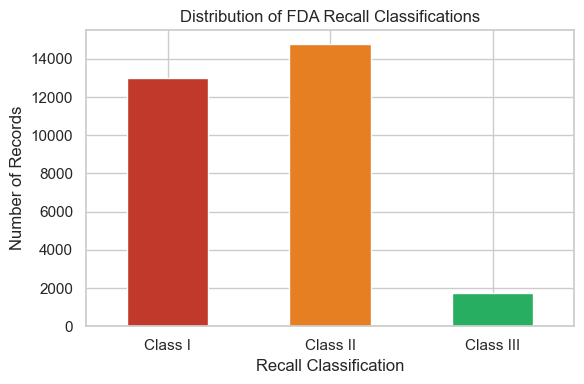

classification
Class I      44.0
Class II     50.0
Class III     6.0
Name: count, dtype: float64
Majority-class baseline accuracy: 0.5


In [13]:
#EXPLORATORY DATA ANALYSIS (EDA) Plot the class distribution
counts = df_clean["classification"].value_counts().reindex(class_order)

counts.plot(kind="bar", color=colors, figsize=(6, 4))
plt.title("Distribution of FDA Recall Classifications")
plt.xlabel("Recall Classification")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print((counts / counts.sum() * 100).round(1))
print("Majority-class baseline accuracy:", round(counts.max() / counts.sum(), 3))

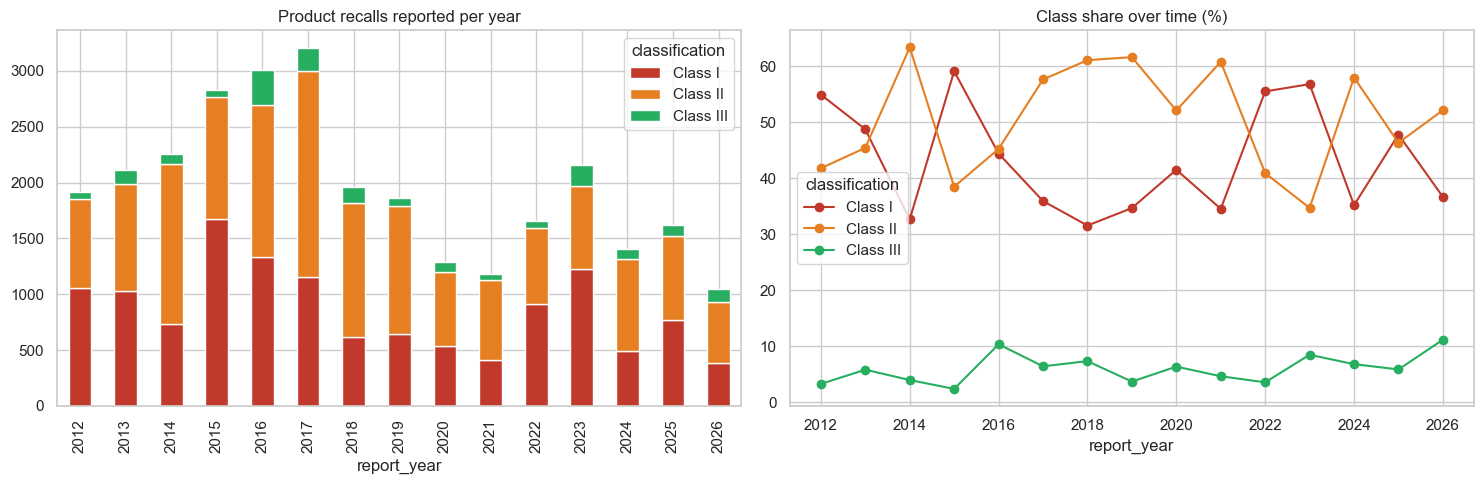

2026 is a partial year, data ends on 2026-10-14


In [14]:
#checks whether recall volume and the class mix change across years (trend / drift)

df_clean["report_year"] = df_clean["report_date"].dt.year
df_clean["report_month"] = df_clean["report_date"].dt.month

yearly = pd.crosstab(df_clean["report_year"], df_clean["classification"])
yearly_pct = yearly.div(yearly.sum(axis=1), axis=0) * 100
# left: stacked counts; right: class share over time
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
yearly.plot(kind="bar", stacked=True, ax=axes[0], color=colors)
axes[0].set_title("Product recalls reported per year")
yearly_pct.plot(marker="o", ax=axes[1], color=colors)
axes[1].set_title("Class share over time (%)")
plt.tight_layout()
plt.show()
print("2026 is a partial year, data ends on", df_clean["report_date"].max().date())

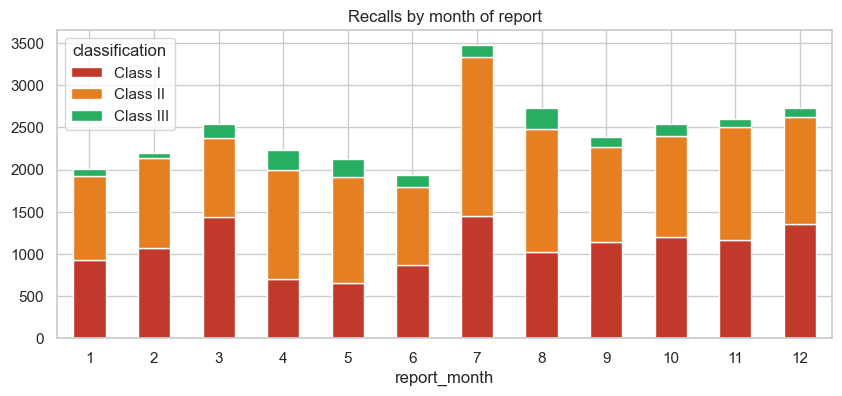

Chi-square (month vs class): chi2 = 825.5 , p-value = 2.298183634743254e-160


In [15]:
#tests whether the class mix depends on the month. Chi-square checks if two categorical variables are associated (small p-value = yes).
# contingency table: month x class
month_table = pd.crosstab(df_clean["report_month"], df_clean["classification"])
month_table.plot(kind="bar", stacked=True, color=colors, figsize=(10, 4))
plt.title("Recalls by month of report")
plt.xticks(rotation=0)
plt.show()

chi2, p, dof, expected = stats.chi2_contingency(month_table)
print("Chi-square (month vs class): chi2 =", round(chi2, 1), ", p-value =", p)

In [16]:
# keyword lists for each hazard type (the first matching group wins)
#turns free text into an interpretable category (pathogen, allergen, ...). Order matters: the most dangerous group is checked first, so a recall mentioning both Listeria and 'milk' is labelled Pathogen.
pathogen_words = ["listeria", "salmonella", "e. coli", "e.coli", "escherichia", "clostridium", "botulinum", "botulism",
                  "campylobacter", "norovirus", "hepatitis", "cronobacter", "vibrio", "shigella", "staphylococc",
                  "bacillus", "pathogen", "monocytogenes", "cyclospora", "enterobacter", "yersinia"]
allergen_words = ["undeclared", "not declared", "does not declare", "failed to declare", "allergen", "milk", "egg", "peanut",
                  "tree nut", "walnut", "almond", "cashew", "pecan", "soy", "wheat", "gluten", "sesame", "fish",
                  "shellfish", "crustacean", "sulfite", "sulphite", "allergic"]
foreign_words = ["foreign", "glass", "metal", "plastic", "wood", "stone", "rubber", "fragment", "piece of", "insect", "bone", "hard object"]
chemical_words = ["pesticide", "lead ", "mercury", "aflatoxin", "toxin", "histamine", "melamine", "chemical", "contaminat",
                  "heavy metal", "cadmium", "arsenic", "mycotoxin", "ochratoxin", "patulin", "sanitizer", "cleaning", "dioxin",
                  "sudan", "sildenafil", "tadalafil"]
spoilage_words = ["mold", "mould", "spoil", "yeast", "decompos", "off odor", "off-odor", "off flavor", "off-flavor", "rancid",
                  "swollen", "bloat", "leak", "underprocess", "under-process", "temperature", "sterility", "low acid",
                  "acidified", "insanitary", "sanitary"]
label_words = ["label", "packag", "mislabel", "misbrand", "incorrect", "nutrition", "expiration", "date code", "lot code",
               "wrong", "not listed", "ingredient"]

def get_reason_category(text):
    text = text.lower()
    if any(word in text for word in pathogen_words):
        return "Pathogen"
    if any(word in text for word in allergen_words):
        return "Undeclared allergen"
    if any(word in text for word in foreign_words):
        return "Foreign material"
    if any(word in text for word in chemical_words):
        return "Chemical / toxin"
    if any(word in text for word in spoilage_words):
        return "Spoilage / quality"
    if any(word in text for word in label_words):
        return "Labelling / packaging"
    return "Other"

df_clean["reason_category"] = df_clean["reason_for_recall"].apply(get_reason_category)
df_clean["reason_category"].value_counts()

reason_category
Pathogen                 12595
Undeclared allergen       9217
Foreign material          2387
Other                     2159
Spoilage / quality        1235
Labelling / packaging      986
Chemical / toxin           924
Name: count, dtype: int64

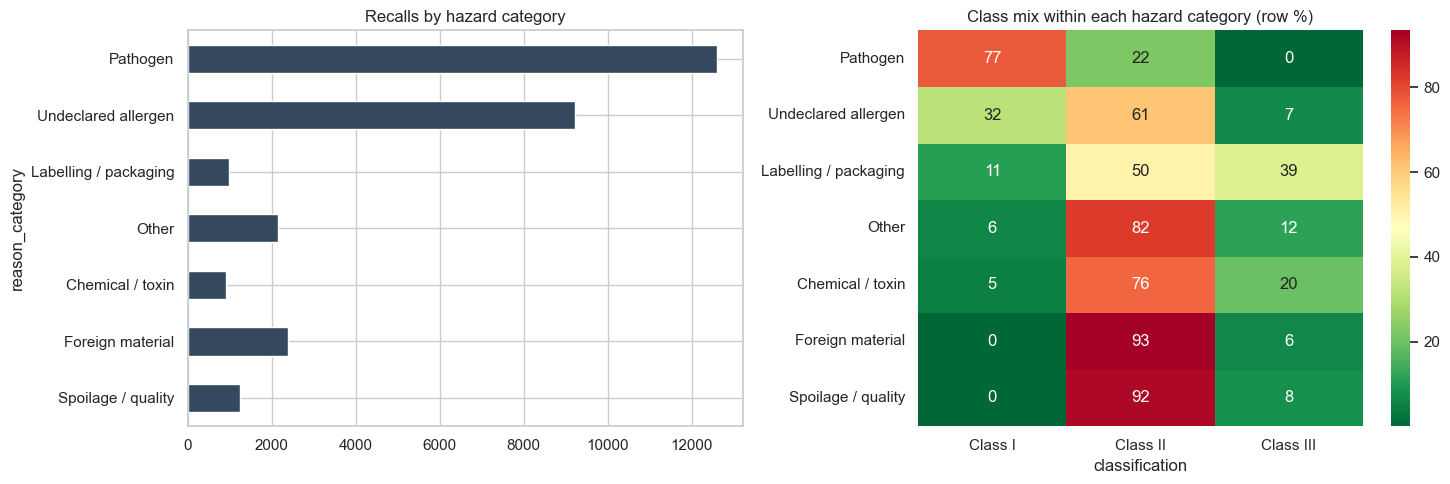

In [17]:
#shows which hazards are linked with severe recalls (e.g. pathogens -> Class I). The heatmap shows row percentages.
cat_table = pd.crosstab(df_clean["reason_category"], df_clean["classification"])
cat_pct = cat_table.div(cat_table.sum(axis=1), axis=0) * 100
cat_pct = cat_pct.sort_values("Class I", ascending=False)
# left: how many recalls per hazard; right: heatmap of class mix
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_clean["reason_category"].value_counts().loc[cat_pct.index].plot(kind="barh", ax=axes[0], color="#34495e")
axes[0].invert_yaxis()
axes[0].set_title("Recalls by hazard category")
sns.heatmap(cat_pct, annot=True, fmt=".0f", cmap="RdYlGn_r", ax=axes[1])
axes[1].set_title("Class mix within each hazard category (row %)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

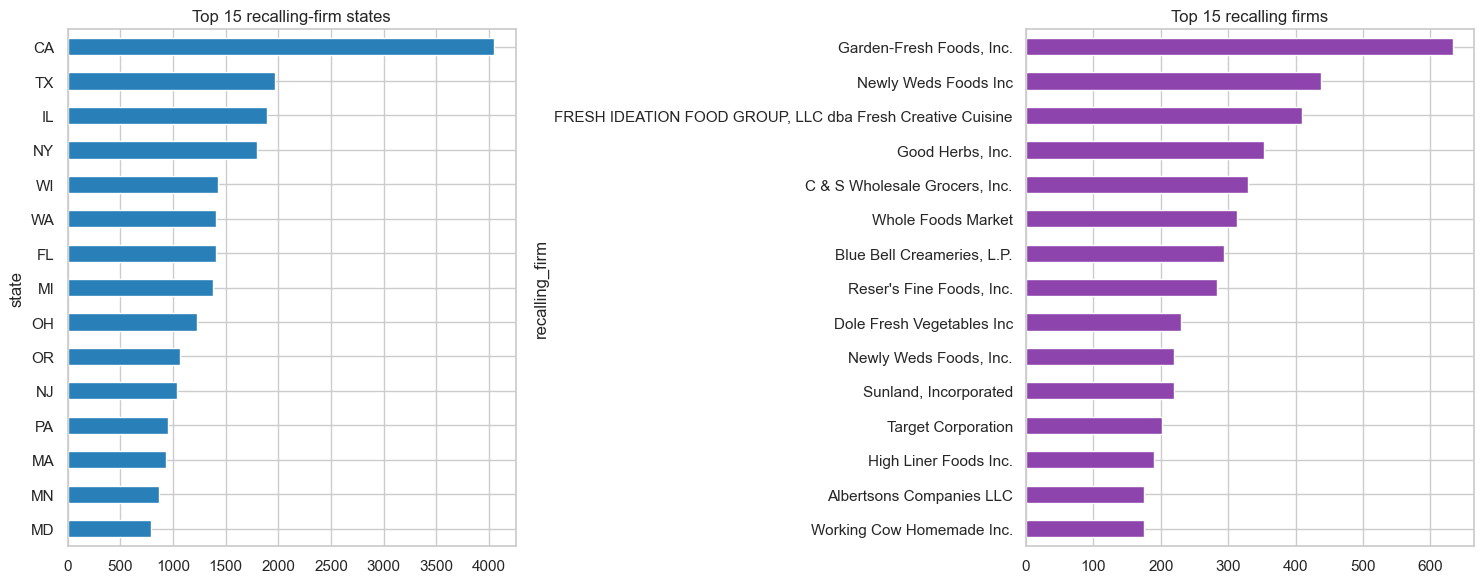

Distinct firms: 5534
Share of recalls from the US: 98.5 %


In [18]:
# 15 most frequent states / firms
top_states = df_clean["state"].value_counts().head(15)
top_firms = df_clean["recalling_firm"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_states.plot(kind="barh", ax=axes[0], color="#2980b9")
axes[0].invert_yaxis()
axes[0].set_title("Top 15 recalling-firm states")
top_firms.plot(kind="barh", ax=axes[1], color="#8e44ad")
axes[1].invert_yaxis()
axes[1].set_title("Top 15 recalling firms")
plt.tight_layout()
plt.show()

print("Distinct firms:", df_clean["recalling_firm"].nunique())
print("Share of recalls from the US:", round((df_clean["country"] == "United States").mean() * 100, 1), "%")

In [19]:
#Association of categorical features with the class (chi-square + Cramer's V)
# effect-size measure for categorical association (0 = none, 1 = perfect)
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    k = min(table.shape) - 1
    return np.sqrt(chi2 / (n * k))

rows = []
for col in ["voluntary_mandated", "initial_firm_notification", "state", "country", "reason_category", "status", "report_year", "report_month"]:
    table = pd.crosstab(df_clean[col], df_clean["classification"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    rows.append([col, round(chi2, 1), p, round(cramers_v(df_clean[col], df_clean["classification"]), 3)])

assoc = pd.DataFrame(rows, columns=["feature", "chi2", "p_value", "cramers_V"])
assoc.sort_values("cramers_V", ascending=False)

,feature,chi2,p_value,cramers_V
4,reason_category,13299.6,0.000000e+00,0.475
2,state,3142.1,0.000000e+00,0.231
1,initial_firm_notification,1876.5,0.000000e+00,0.178
6,report_year,1457.8,7.478082e-290,0.157
7,report_month,825.5,2.298184e-160,0.118
0,voluntary_mandated,429.4,1.241369e-91,0.085
3,country,348.1,1.948273e-41,0.077
5,status,44.8,4.298549e-09,0.028


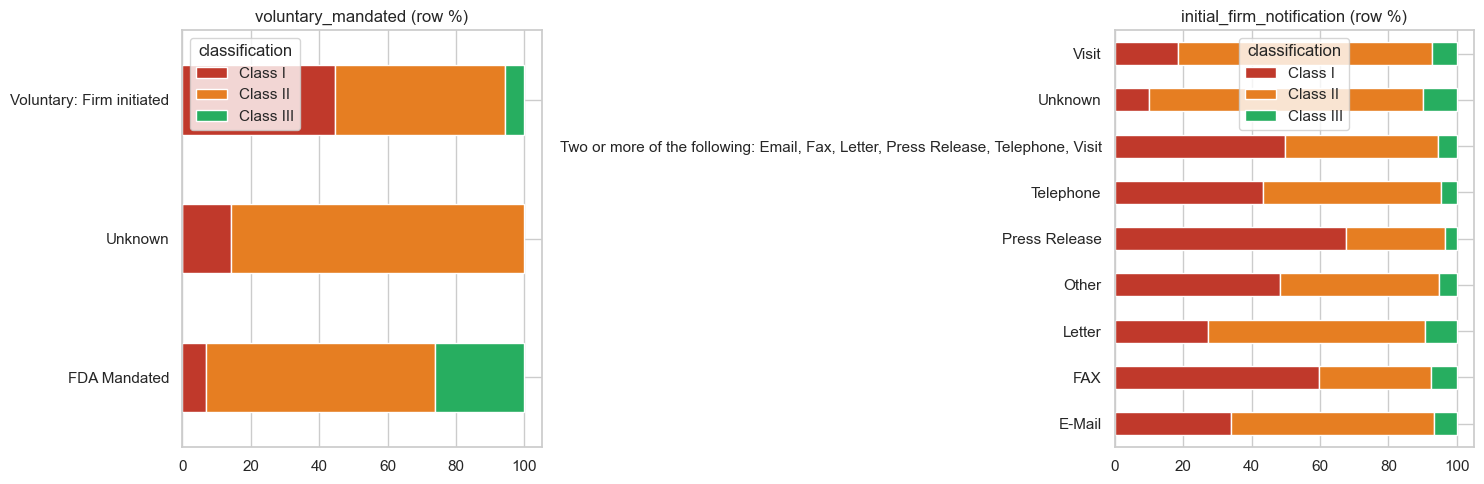

In [20]:
# Voluntary/mandated and firm notification vs class
# visual check of how these process fields relate to severity (row % stacked bars).
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, ["voluntary_mandated", "initial_firm_notification"]):
    table = pd.crosstab(df_clean[col], df_clean["classification"], normalize="index") * 100
    table.plot(kind="barh", stacked=True, ax=ax, color=colors)
    ax.set_title(col + " (row %)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [21]:
#FEATURE ENGINEERING
# Helper functions to extract quantity and number of states
#'product_quantity' and 'distribution_pattern' are messy text. Scale of a recall (how much, how widely) is a likely driver of severity, so we turn them into numbers.
state_codes = ["AL","AK","AZ","AR","CA","CO","CT","DE","FL","GA","HI","ID","IL","IN","IA","KS","KY","LA","ME","MD","MA","MI","MN","MS","MO",
               "MT","NE","NV","NH","NJ","NM","NY","NC","ND","OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT","VA","WA","WV","WI","WY","DC","PR"]
state_names = ["alabama","alaska","arizona","arkansas","california","colorado","connecticut","delaware","florida","georgia","hawaii","idaho",
               "illinois","indiana","iowa","kansas","kentucky","louisiana","maine","maryland","massachusetts","michigan","minnesota",
               "mississippi","missouri","montana","nebraska","nevada","new hampshire","new jersey","new mexico","new york","north carolina",
               "north dakota","ohio","oklahoma","oregon","pennsylvania","rhode island","south carolina","south dakota","tennessee","texas",
               "utah","vermont","virginia","washington","west virginia","wisconsin","wyoming","district of columbia","puerto rico"]

def get_quantity(text):
    """Take the biggest number in the text (3.2 million -> 3200000). No number -> missing."""
    text = str(text).lower()
    numbers = re.findall(r"\d[\d,]*\.?\d*", text)
    values = []
    for n in numbers:
        try:
            values.append(float(n.replace(",", "").rstrip(".")))
        except ValueError:
            pass
    if len(values) == 0:
        return np.nan
    biggest = max(values)
    if "million" in text:
        biggest = biggest * 1000000
    return biggest
# count distinct states mentioned (as codes or full names)
def count_states(text):
    text = str(text)
    codes_found = set(re.findall(r"\b[A-Z]{2}\b", text)) & set(state_codes)
    names_found = [name for name in state_names if name in text.lower()]
    return max(len(codes_found), len(names_found))

In [22]:
# Create quantity, state-count and distribution flags
#log10 of quantity reduces the huge skew (a few giant recalls). Flags capture 'nationwide' and 'international' distribution.
df_clean["quantity_num"] = df_clean["product_quantity"].apply(get_quantity)
df_clean["log_quantity"] = np.log10(df_clean["quantity_num"].clip(lower=1))
df_clean["n_states"] = df_clean["distribution_pattern"].apply(count_states)

dist = df_clean["distribution_pattern"].str.lower()
df_clean["is_nationwide"] = dist.str.contains("nationwide|nation wide|nationally|all states|50 states").astype(int)
df_clean["is_international"] = dist.str.contains(
    "canada|mexico|international|worldwide|foreign|export|europe|asia|japan|china|hong kong|korea|united kingdom|australia|bermuda|bahamas|caribbean|israel").astype(int)

print("Quantity found for", round(df_clean["quantity_num"].notna().mean() * 100, 1), "% of rows")
# spot-check 8 random rows to verify the extraction
df_clean[["product_quantity", "quantity_num", "distribution_pattern", "n_states", "is_nationwide", "is_international"]].sample(8, random_state=1)

Quantity found for 87.3 % of rows


,product_quantity,quantity_num,distribution_pattern,n_states,is_nationwide,is_international
24580,146495 pieces,146495.0,AR AZ CA CO FL GA IL IN LA MA MD MI MN MO NC NJ NY OH OR PA TX UT VA WA WI a...,25,0,1
11015,2832 units,2832.0,"Rhode Island, Massachusetts, Connecticut, New Hampshire, Vermont and Maine, ...",7,0,0
7477,9951 cases,9951.0,"CA, IA, IL, MD, MO, NY, RI, TX, WA, WI",10,0,0
26267,"13,341 bags",13341.0,"AZ, CA, GA, ID, IL, IN, KS, MD. Outside the US: Canada",8,0,1
28726,71 cups,71.0,Florida,1,0,0
17252,"1401 Total cases (1103 cases/12 units/2 oz, 258 cases/12 units/6 oz, 40 case...",1401.0,"CT, NY, NJ, RI, PA, Washington D.C. & MA",6,0,0
11591,47 cases (6/12 fl. oz. bottles per case),47.0,"distributed directly to Idaho, California, Oregon and Washington and in Onta...",4,0,1
7379,unknown,NaN,"Two Target Stores 1. 98 Veterans Memorial Highway in Commack, New York 2. 16...",1,0,0


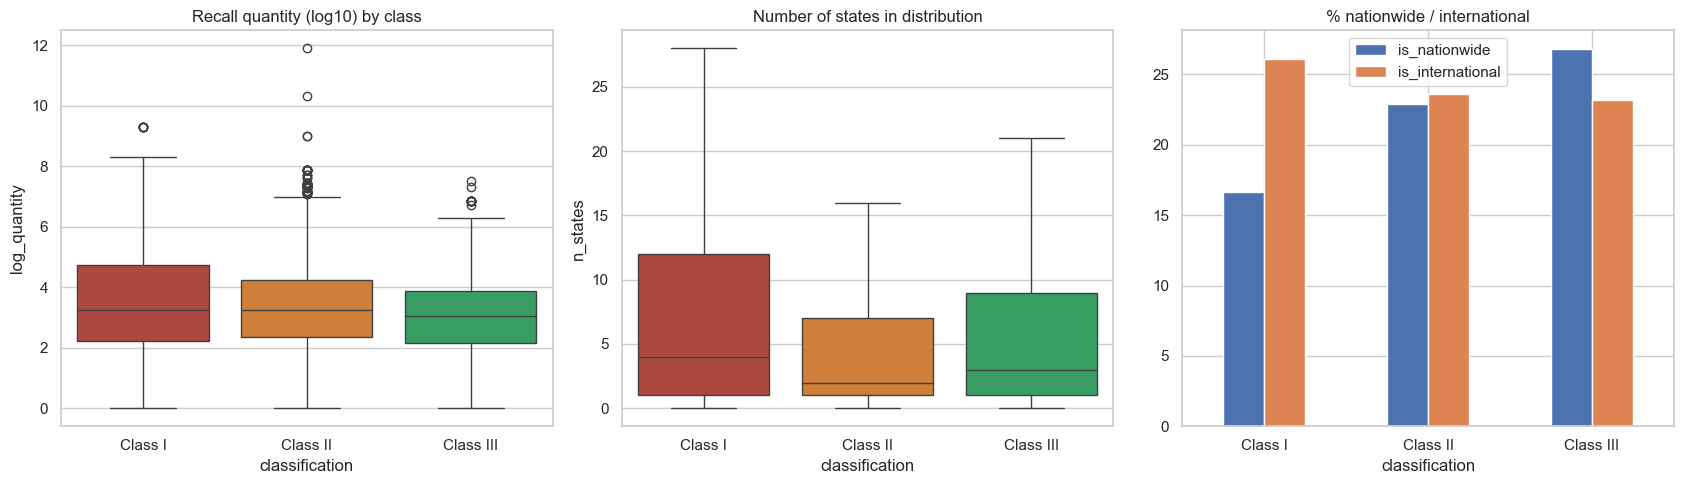

Kruskal-Wallis (quantity vs class): H = 60.6, p = 6.82e-14


,quantity_num,n_states
classification,,
Class I,1803.0,4.0
Class II,1767.0,2.0
Class III,1164.0,3.0


In [23]:
#Do scale and distribution differ by class? (+ Kruskal-Wallis test)
#checks whether the new numeric features are useful. Kruskal-Wallis is a non-parametric test (no normality assumption) comparing 3 groups.
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
# boxplot of quantity per class
sns.boxplot(data=df_clean, x="classification", y="log_quantity", order=class_order, palette=colors, ax=axes[0])
axes[0].set_title("Recall quantity (log10) by class")

sns.boxplot(data=df_clean, x="classification", y="n_states", order=class_order, palette=colors, showfliers=False, ax=axes[1])
axes[1].set_title("Number of states in distribution")

# percentage nationwide / international per class
share = df_clean.groupby("classification")[["is_nationwide", "is_international"]].mean().reindex(class_order) * 100
share.plot(kind="bar", ax=axes[2])
axes[2].set_title("% nationwide / international")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

groups = [df_clean.loc[df_clean["classification"] == c, "log_quantity"].dropna() for c in class_order]
print("Kruskal-Wallis (quantity vs class): H = %.1f, p = %.3g" % stats.kruskal(*groups))
df_clean.groupby("classification")[["quantity_num", "n_states"]].median()

count    29502.0
mean        72.3
std        120.8
min          8.0
25%         33.0
50%         46.0
75%         71.0
max       2270.0
Name: report_lag_days, dtype: float64


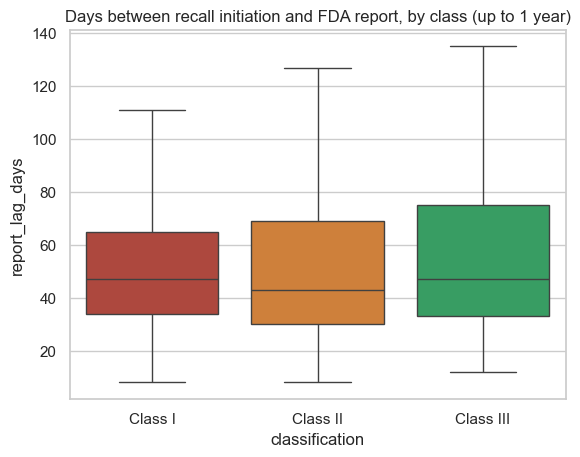

In [24]:
#Report lag (days between recall start and FDA report)
df_clean["report_lag_days"] = (df_clean["report_date"] - df_clean["recall_initiation_date"]).dt.days

print(df_clean["report_lag_days"].describe().round(1))

lag = df_clean[df_clean["report_lag_days"].between(0, 365)]
sns.boxplot(data=lag, x="classification", y="report_lag_days", order=class_order, palette=colors, showfliers=False)
plt.title("Days between recall initiation and FDA report, by class (up to 1 year)")
plt.show()

Distinct recall events: 7918
Products per event: mean 3.73 , median 1.0 , max 409
Events with only ONE class among their products: 97.8 %


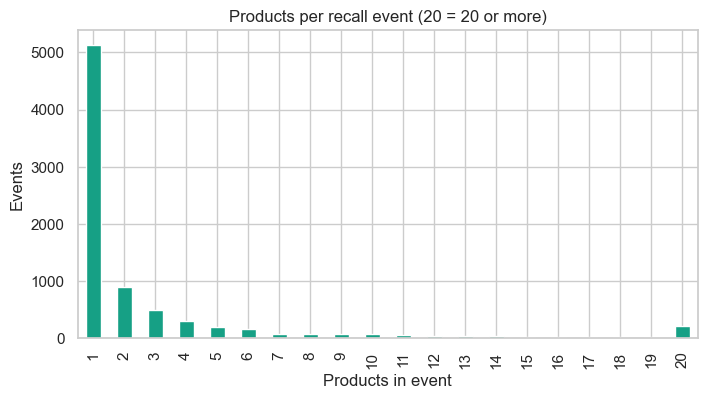

In [25]:

event = df_clean.groupby("event_id").agg(n_products=("recall_number", "size"), n_classes=("classification", "nunique"))

print("Distinct recall events:", len(event))
print("Products per event: mean", round(event["n_products"].mean(), 2), ", median", event["n_products"].median(), ", max", event["n_products"].max())
print("Events with only ONE class among their products:", round((event["n_classes"] == 1).mean() * 100, 1), "%")

event["n_products"].clip(upper=20).value_counts().sort_index().plot(kind="bar", color="#16a085", figsize=(8, 4))
plt.title("Products per recall event (20 = 20 or more)")
plt.xlabel("Products in event")
plt.ylabel("Events")
plt.show()

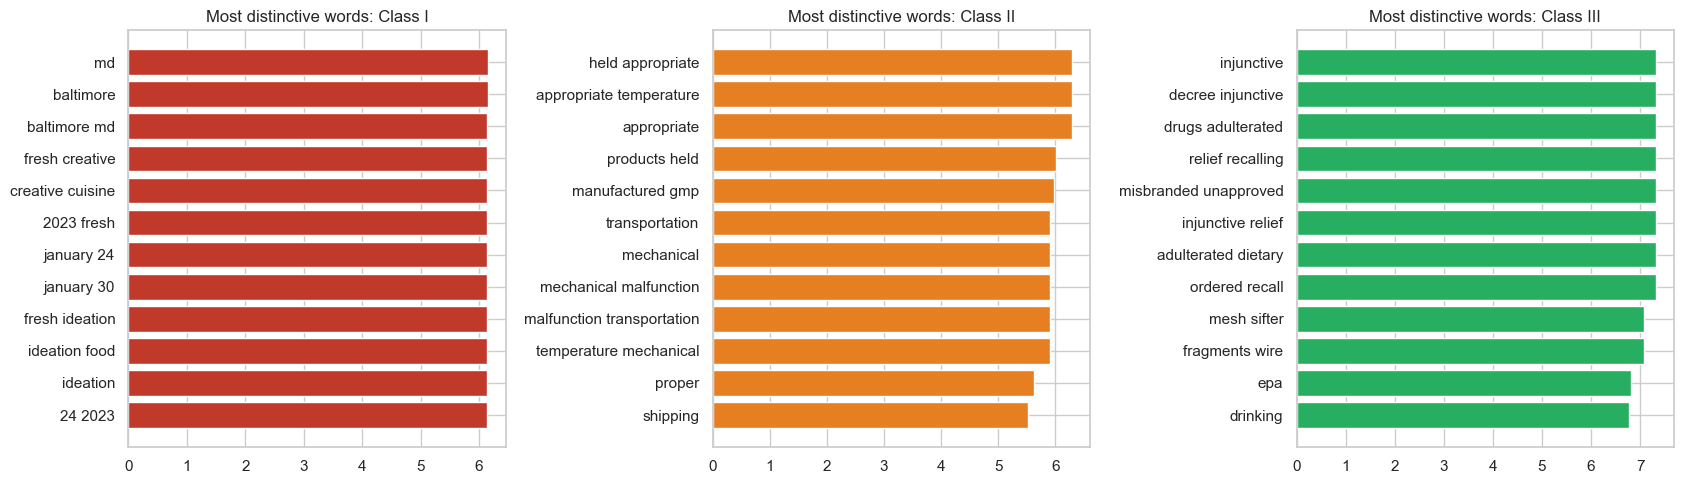

In [26]:
#Most distinctive words per class (log-odds)
from sklearn.feature_extraction.text import CountVectorizer

counter = CountVectorizer(stop_words="english", min_df=15, ngram_range=(1, 2), binary=True)
word_matrix = counter.fit_transform(df_clean["reason_for_recall"].str.lower())
words = np.array(counter.get_feature_names_out())

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, cls, col in zip(axes, class_order, colors):
    in_class = (df_clean["classification"] == cls).values
    a = np.asarray(word_matrix[in_class].sum(axis=0)).ravel() + 1      # word counts inside the class
    b = np.asarray(word_matrix[~in_class].sum(axis=0)).ravel() + 1     # word counts in the other classes
    log_odds = np.log(a / a.sum()) - np.log(b / b.sum())
    top = np.argsort(log_odds)[::-1][:12]
    ax.barh(words[top][::-1], log_odds[top][::-1], color=col)
    ax.set_title("Most distinctive words: " + cls)
plt.tight_layout()
plt.show()

In [27]:
# keyword flags: 1 if any of the words appears in the recall reason, otherwise 0
#Keyword flag features from the recall reason
keywords = {
    "kw_listeria":   ["listeria", "monocytogenes"],
    "kw_salmonella": ["salmonella"],
    "kw_ecoli":      ["e. coli", "e.coli", "escherichia", "stec"],
    "kw_botulism":   ["botulinum", "botulism"],
    "kw_undeclared": ["undeclared", "not declared", "does not declare", "failed to declare", "not listed", "without declaring"],
    "kw_milk":       ["milk", "dairy", "casein", "whey", "lactose"],
    "kw_egg":        ["egg"],
    "kw_peanut":     ["peanut"],
    "kw_treenut":    ["tree nut", "almond", "walnut", "cashew", "pecan", "hazelnut", "pistachio"],
    "kw_soy_wheat":  ["soy", "wheat", "gluten"],
    "kw_sesame":     ["sesame"],
    "kw_fish_shell": ["fish", "shellfish", "crustacean", "shrimp"],
    "kw_sulfite":    ["sulfite", "sulphite"],
    "kw_foreign":    ["foreign", "glass", "metal", "plastic", "fragment", "stone", "insect"],
    "kw_mold":       ["mold", "mould", "yeast", "spoil"],
    "kw_chemical":   ["pesticide", "lead ", "toxin", "histamine", "chemical", "melamine", "aflatoxin"],
    "kw_may_cause":  ["may cause", "could cause", "potential", "possible", "possibility"],
    "kw_illness":    ["illness", "infection", "sick", "death", "outbreak", "hospital"],
    "kw_label":      ["label", "packag", "mislabel", "misbrand"],
    "kw_fda_sample": ["fda sample", "routine sampl", "sampling", "tested positive", "positive for", "test results"],
}

reason_lower = df_clean["reason_for_recall"].str.lower()
for name, word_list in keywords.items():
    df_clean[name] = reason_lower.apply(lambda text: int(any(w in text for w in word_list)))

(df_clean[list(keywords)].mean() * 100).round(1).sort_values(ascending=False)

kw_may_cause     29.8
kw_listeria      25.5
kw_undeclared    25.3
kw_salmonella    12.5
kw_milk          12.4
kw_label         11.0
kw_soy_wheat      9.7
kw_foreign        8.2
kw_peanut         6.3
kw_treenut        5.5
kw_fda_sample     4.6
kw_egg            3.4
kw_illness        2.5
kw_mold           2.4
kw_chemical       1.9
kw_ecoli          1.9
kw_fish_shell     1.7
kw_botulism       1.3
kw_sulfite        1.0
kw_sesame         0.7
dtype: float64

In [82]:
#text length, missing quantity/codes and mandated status can carry signal. Log transforms tame skewed values.
# simple length / missing / yes-no features
df_clean["reason_words"] = df_clean["reason_for_recall"].str.split().str.len()
df_clean["desc_words"] = df_clean["product_description"].str.split().str.len()
df_clean["quantity_missing"] = df_clean["quantity_num"].isna().astype(int)
df_clean["codes_missing"] = df_clean["code_info"].str.lower().isin(["", "no codes", "none", "n/a", "unknown", "not available"]).astype(int)
df_clean["is_mandated"] = (df_clean["voluntary_mandated"] == "FDA Mandated").astype(int)
df_clean["report_lag_log"] = np.log1p(df_clean["report_lag_days"].clip(lower=0, upper=730))

# how many products are in the same recall event
df_clean["event_size"] = df_clean.groupby("event_id")["recall_number"].transform("size")
df_clean["log_event_size"] = np.log1p(df_clean["event_size"])

In [29]:
# firm history: how many EARLIER recall events did the same firm have? (only past events are counted)
events = df_clean.groupby("event_id").agg(firm=("recalling_firm", "first"), first_report=("report_date", "min")).reset_index()
events = events.sort_values("first_report")
events["firm_prior_events"] = events.groupby("firm").cumcount()      # 0 for the first recall, 1 for the second, ...

df_clean["firm_prior_events"] = df_clean["event_id"].map(events.set_index("event_id")["firm_prior_events"])
df_clean["firm_prior_log"] = np.log1p(df_clean["firm_prior_events"])
df_clean[["recalling_firm", "event_id", "firm_prior_events"]].head()

,recalling_firm,event_id,firm_prior_events
0,WinCo Foods LLC,99946,1
1,QUESO PALMITA GP LLC,99933,0
2,J K Patisserie & Bakery LLC,99823,0
3,Saint Francis Apizza LLC,100043,0
4,Saint Francis Apizza LLC,100043,0


In [30]:
# group rare values together
#states/countries with very few rows create noisy, unstable features. We keep the 25 biggest states and group the rest as 'Other'.
top_25_states = df_clean["state"].value_counts().head(25).index
df_clean["state_grp"] = df_clean["state"].where(df_clean["state"].isin(top_25_states), "Other")
df_clean["country_grp"] = df_clean["country"].where(df_clean["country"].isin(["United States", "Canada"]), "Other")
df_clean["report_month_c"] = df_clean["report_month"].astype(str)

In [31]:
#TRAIN / TEST SPLIT
# Define predictors (X), target (y) and groups
text_cols = ["reason_for_recall", "product_description"]
cat_cols = ["state_grp", "country_grp", "voluntary_mandated", "initial_firm_notification", "reason_category", "report_month_c"]
num_cols = ["log_quantity", "n_states", "report_lag_log", "reason_words", "desc_words", "log_event_size", "firm_prior_log"]
flag_cols = ["is_nationwide", "is_international", "quantity_missing", "codes_missing", "is_mandated"] + list(keywords)

all_features = text_cols + cat_cols + num_cols + flag_cols

X = df_clean[all_features].copy()
y = df_clean["classification"]
groups = df_clean["event_id"]

print("Predictor dataset:", X.shape)
print("Target dataset:", y.shape)

Predictor dataset: (29503, 40)
Target dataset: (29503,)


In [32]:
#Grouped, stratified train/test split (80/20)
# StratifiedGroupKFold keeps class proportions similar (stratified) and  all products of one event on the same side (grouped). 
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)
y_train = y.iloc[train_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)
g_train = groups.iloc[train_idx].reset_index(drop=True)
g_test = groups.iloc[test_idx].reset_index(drop=True)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTraining class distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("\nTesting class distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(1))
print("\nCommon event IDs between train and test:", len(set(g_train) & set(g_test)))

Training data: (23603, 40)
Testing data: (5900, 40)

Training class distribution (%):
classification
Class II     50.0
Class I      44.0
Class III     6.0
Name: proportion, dtype: float64

Testing class distribution (%):
classification
Class II     50.0
Class I      44.0
Class III     6.0
Name: proportion, dtype: float64

Common event IDs between train and test: 0


In [33]:
#FEATURE MATRIX BUILDER
#Functions that turn the table into a numeric matrix
# TF-IDF converts text to weighted word vectors, one-hot encodes categories, imputer+scaler prepare numbers. Tools are FIT ONLY on training data and then applied to validation/test data - otherwise information from the test set leaks into training.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from scipy.sparse import hstack, csr_matrix


In [34]:
# learn the tools on TRAIN data and return the training matrix
def fit_features(train, max_reason=30000, max_desc=20000, scale=True,
                 use_reason=True, use_desc=True, use_cat=True, use_num=True, use_flags=True, cats=cat_cols):
    """Learn the TF-IDF / encoder / scaler from the TRAIN data and return the train matrix + the fitted tools."""
    tools = {}
    blocks = []
    if use_reason:
        tools["reason"] = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=max_reason, sublinear_tf=True)
        blocks.append(tools["reason"].fit_transform(train["reason_for_recall"]))
    if use_desc:
        tools["desc"] = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=max_desc, sublinear_tf=True)
        blocks.append(tools["desc"].fit_transform(train["product_description"]))
    if use_cat:
        tools["cats"] = cats
        tools["cat"] = OneHotEncoder(handle_unknown="ignore", min_frequency=20)
        blocks.append(tools["cat"].fit_transform(train[cats]))
    if use_num:
        tools["imputer"] = SimpleImputer(strategy="median")
        numbers = tools["imputer"].fit_transform(train[num_cols])
        if scale:
            tools["scaler"] = StandardScaler()
            numbers = tools["scaler"].fit_transform(numbers)
        blocks.append(csr_matrix(numbers))
    if use_flags:
        tools["flags"] = True
        blocks.append(csr_matrix(train[flag_cols].values.astype(float)))
    return hstack(blocks).tocsr(), tools


In [35]:
# transform NEW data with the already-fitted tools (no re-fitting)
def apply_features(data, tools):
    """Use the already-fitted tools to transform new data (test / validation)."""
    blocks = []
    if "reason" in tools:
        blocks.append(tools["reason"].transform(data["reason_for_recall"]))
    if "desc" in tools:
        blocks.append(tools["desc"].transform(data["product_description"]))
    if "cat" in tools:
        blocks.append(tools["cat"].transform(data[tools["cats"]]))
    if "imputer" in tools:
        numbers = tools["imputer"].transform(data[num_cols])
        if "scaler" in tools:
            numbers = tools["scaler"].transform(numbers)
        blocks.append(csr_matrix(numbers))
    if "flags" in tools:
        blocks.append(csr_matrix(data[flag_cols].values.astype(float)))
    return hstack(blocks).tocsr()

In [36]:
# readable names of all columns, used later for interpretation
def get_feature_names(tools):
    names = []
    if "reason" in tools: names += ["reason: " + w for w in tools["reason"].get_feature_names_out()]
    if "desc" in tools:   names += ["desc: " + w for w in tools["desc"].get_feature_names_out()]
    if "cat" in tools:    names += ["cat: " + n for n in tools["cat"].get_feature_names_out(tools["cats"])]
    if "imputer" in tools: names += ["num: " + c for c in num_cols]
    if "flags" in tools:  names += ["flag: " + c for c in flag_cols]
    return names

In [37]:
print("Functions defined:", callable(fit_features), callable(apply_features), callable(get_feature_names))
print("Training rows:", len(X_train))
print("Reason columns:", len(cat_cols), "categorical columns")

Functions defined: True True True
Training rows: 23603
Reason columns: 6 categorical columns


In [38]:
# Build the two feature versions
#linear models like a big, scaled matrix ('wide'); tree models work better with fewer, unscaled features ('lean').
X_train_wide, tools_wide = fit_features(X_train)
print("Wide feature matrix (train):", X_train_wide.shape)

X_train_lean, tools_lean = fit_features(X_train, max_reason=2500, max_desc=1500, scale=False)
print("Lean feature matrix (train):", X_train_lean.shape)

Wide feature matrix (train): (23603, 35592)
Lean feature matrix (train): (23603, 4092)


In [80]:
# MODEL COMPARISON (CROSS-VALIDATION)
#Folds are grouped by event, and features are re-learned inside each fold to prevent leakage.
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
                             classification_report, confusion_matrix, recall_score)

# 3 cross-validation folds on the training data; whole events stay together in one fold
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
folds = list(cv.split(X_train, y_train, g_train))

def build_folds(splits, **settings):
    """For every fold: learn the features on the fold's training part, apply them to its validation part."""
    fold_data = []
    for tr, va in splits:
        X_a, tools = fit_features(X_train.iloc[tr], **settings)
        X_b = apply_features(X_train.iloc[va], tools)
        fold_data.append((X_a, X_b, y_train.iloc[tr], y_train.iloc[va]))
    return fold_data

wide_folds = build_folds(folds)                                                  # for linear models
lean_folds = build_folds(folds, max_reason=2500, max_desc=1500, scale=False) # for tree models
nb_folds = build_folds(folds, use_num=False)                                     # Naive Bayes cannot take negative numbers
print("Folds ready:", len(wide_folds))

Folds ready: 3


In [81]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Groups:", g_train.shape)
print("Feature functions:", callable(fit_features), callable(apply_features))

X_train: (23603, 40)
y_train: (23603,)
Groups: (23603,)
Feature functions: True True


In [41]:
#Cross-validate six candidate models
#compare different model families fairly with several metrics. Macro-F1 is the headline metric because it treats all classes equally (important with a rare Class III). The Dummy model is the 'no-skill' baseline; real models must beat it.
def cv_score(model, fold_data):
    """Fit on each fold and return the average scores."""
    scores = {"accuracy": [], "balanced_acc": [], "f1_macro": [], "f1_weighted": [], "mcc": []}
    for X_a, X_b, y_a, y_b in fold_data:
        model.fit(X_a, y_a)
        pred = model.predict(X_b)
        scores["accuracy"].append(accuracy_score(y_b, pred))
        scores["balanced_acc"].append(balanced_accuracy_score(y_b, pred))
        scores["f1_macro"].append(f1_score(y_b, pred, average="macro"))
        scores["f1_weighted"].append(f1_score(y_b, pred, average="weighted"))
        scores["mcc"].append(matthews_corrcoef(y_b, pred))
    return {name: np.mean(values) for name, values in scores.items()}

models = {
    "Dummy (stratified)":  (DummyClassifier(strategy="stratified", random_state=42), lean_folds),
    "Logistic Regression": (LogisticRegression(C=2.0, max_iter=300, class_weight="balanced"), wide_folds),
    "Linear SVM":          (LinearSVC(C=0.3, class_weight="balanced", random_state=42), wide_folds),
    "Complement NB":       (ComplementNB(alpha=0.3), nb_folds),
    "Random Forest":       (RandomForestClassifier(n_estimators=150, min_samples_leaf=2, max_features="sqrt",
                                                   class_weight="balanced_subsample", n_jobs=1, random_state=42), lean_folds),
    "LightGBM":            (LGBMClassifier(n_estimators=250, learning_rate=0.08, num_leaves=31, colsample_bytree=0.4,
                                           subsample=0.8, subsample_freq=1, class_weight="balanced",
                                           n_jobs=1, random_state=42, verbose=-1), lean_folds),
}

results = {}
for name, (model, fold_data) in models.items():
    start = time.time()
    results[name] = cv_score(model, fold_data)
    results[name]["seconds"] = round(time.time() - start, 1)
    print(name, "-> macro-F1:", round(results[name]["f1_macro"], 3), "| accuracy:", round(results[name]["accuracy"], 3))

cv_table = pd.DataFrame(results).T.sort_values("f1_macro", ascending=False)
cv_table.round(3)

Dummy (stratified) -> macro-F1: 0.335 | accuracy: 0.448
Logistic Regression -> macro-F1: 0.633 | accuracy: 0.757
Linear SVM -> macro-F1: 0.623 | accuracy: 0.764
Complement NB -> macro-F1: 0.581 | accuracy: 0.754
Random Forest -> macro-F1: 0.574 | accuracy: 0.757
LightGBM -> macro-F1: 0.6 | accuracy: 0.751


,accuracy,balanced_acc,f1_macro,f1_weighted,mcc,seconds
Logistic Regression,0.757,0.624,0.633,0.753,0.559,21.2
Linear SVM,0.764,0.607,0.623,0.756,0.566,42.8
LightGBM,0.751,0.588,0.600,0.741,0.544,174.2
Complement NB,0.754,0.571,0.581,0.741,0.542,0.8
Random Forest,0.757,0.566,0.574,0.741,0.547,95.5
Dummy (stratified),0.448,0.335,0.335,0.448,0.003,0.5


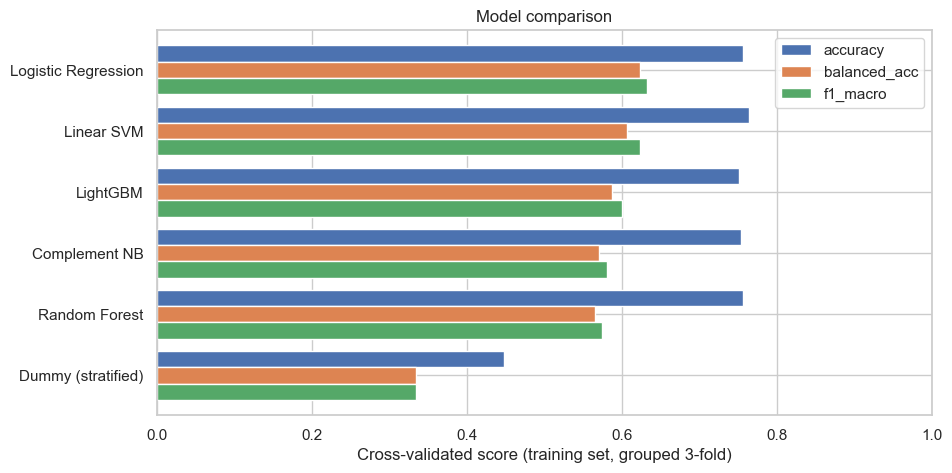

In [42]:
# visual summary of accuracy, balanced accuracy and macro-F1 for all models.
cv_table[["accuracy", "balanced_acc", "f1_macro"]].round(3).plot(kind="barh", figsize=(10, 5), width=0.8)
plt.gca().invert_yaxis()
plt.xlim(0, 1)
plt.xlabel("Cross-validated score (training set, grouped 3-fold)")
plt.title("Model comparison")
plt.show()

In [43]:
#effect of class weighting shows why we use class_weight='balanced'. Without it the model favours big classes;
rows = []
for label, weight in [("No weighting", None), ("class_weight='balanced'", "balanced")]:
    all_true, all_pred = [], []
    for X_a, X_b, y_a, y_b in wide_folds:
        model = LogisticRegression(C=2.0, max_iter=300, class_weight=weight)
        model.fit(X_a, y_a)
        all_pred += list(model.predict(X_b))
        all_true += list(y_b)
    recalls = recall_score(all_true, all_pred, labels=class_order, average=None)
    rows.append([label, accuracy_score(all_true, all_pred), f1_score(all_true, all_pred, average="macro"),
                 recalls[0], recalls[1], recalls[2]])

pd.DataFrame(rows, columns=["setting", "accuracy", "macro_F1", "recall_Class I", "recall_Class II", "recall_Class III"]).set_index("setting").round(3)

,accuracy,macro_F1,recall_Class I,recall_Class II,recall_Class III
setting,,,,,
No weighting,0.762,0.583,0.825,0.784,0.111
class_weight='balanced',0.757,0.633,0.833,0.746,0.294


In [44]:
#Leakage demonstration - random split vs grouped split
from sklearn.model_selection import StratifiedKFold

random_splits = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=42).split(X_train, y_train))
random_folds = build_folds(random_splits)

lr_test = LogisticRegression(C=2.0, max_iter=300, class_weight="balanced")
leak = pd.DataFrame({
    "Random row split (leaky)":  cv_score(lr_test, random_folds),
    "Grouped by event (honest)": cv_score(lr_test, wide_folds),
}).T[["accuracy", "f1_macro"]].round(3)
leak["inflation_in_macro_F1"] = (leak["f1_macro"] - leak.loc["Grouped by event (honest)", "f1_macro"]).round(3)
leak

,accuracy,f1_macro,inflation_in_macro_F1
Random row split (leaky),0.908,0.863,0.23
Grouped by event (honest),0.757,0.633,0.00


In [45]:
# HYPERPARAMETER TUNING
#Tune Logistic Regression (regularisation C)
# C controls regularisation: small C = simpler model, large C = more flexible. 
lr_results = []
for C_value in [0.25, 0.5, 1, 2, 4, 8]:
    model = LogisticRegression(C=C_value, max_iter=400, class_weight="balanced")
    score = cv_score(model, wide_folds)["f1_macro"]
    lr_results.append([C_value, score])
    print("C =", C_value, "-> macro-F1:", round(score, 4))

lr_res = pd.DataFrame(lr_results, columns=["C", "cv_macro_F1"])
best_C = lr_res.sort_values("cv_macro_F1", ascending=False).iloc[0]["C"]
print("\nBest C:", best_C)

C = 0.25 -> macro-F1: 0.6338
C = 0.5 -> macro-F1: 0.6369
C = 1 -> macro-F1: 0.6355
C = 2 -> macro-F1: 0.6328
C = 4 -> macro-F1: 0.6303
C = 8 -> macro-F1: 0.6236

Best C: 0.5


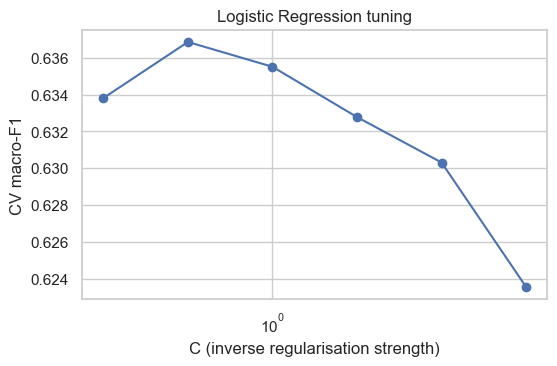

In [46]:
# Plot the tuning curve
#shows how sensitive the score is to C 
plt.figure(figsize=(6, 3.5))
plt.plot(lr_res["C"], lr_res["cv_macro_F1"], marker="o")
plt.xscale("log")
plt.xlabel("C (inverse regularisation strength)")
plt.ylabel("CV macro-F1")
plt.title("Logistic Regression tuning")
plt.show()

In [47]:
#Tune LightGBM (small search) :capture non liner relationship and interactions among feature
#boosting performance depends on settings: number of trees, learning rate, leaves, feature sampling and regularisation. We test 6 sensible combinations (a small random-style search keeps runtime short).
gbm_options = [
    dict(n_estimators=150, learning_rate=0.12, num_leaves=15, colsample_bytree=0.2, min_child_samples=40, reg_lambda=5),
    dict(n_estimators=250, learning_rate=0.08, num_leaves=31, colsample_bytree=0.4, min_child_samples=20, reg_lambda=1),
    dict(n_estimators=350, learning_rate=0.05, num_leaves=63, colsample_bytree=0.6, min_child_samples=10, reg_lambda=0),
    dict(n_estimators=250, learning_rate=0.12, num_leaves=15, colsample_bytree=0.4, min_child_samples=40, reg_lambda=1),
    dict(n_estimators=150, learning_rate=0.08, num_leaves=63, colsample_bytree=0.2, min_child_samples=20, reg_lambda=5),
    dict(n_estimators=350, learning_rate=0.05, num_leaves=31, colsample_bytree=0.4, min_child_samples=20, reg_lambda=0),
]

gbm_results = []
start = time.time()
for options in gbm_options:
    model = LGBMClassifier(subsample=0.8, subsample_freq=1, class_weight="balanced", n_jobs=1, random_state=42, verbose=-1, **options)
    score = cv_score(model, lean_folds)["f1_macro"]
    gbm_results.append(dict(options, cv_macro_F1=score))
    print(options, "-> macro-F1:", round(score, 4))
print("done in", round(time.time() - start), "seconds")

gbm_res = pd.DataFrame(gbm_results).sort_values("cv_macro_F1", ascending=False)
gbm_res.round(4)

{'n_estimators': 150, 'learning_rate': 0.12, 'num_leaves': 15, 'colsample_bytree': 0.2, 'min_child_samples': 40, 'reg_lambda': 5} -> macro-F1: 0.6163
{'n_estimators': 250, 'learning_rate': 0.08, 'num_leaves': 31, 'colsample_bytree': 0.4, 'min_child_samples': 20, 'reg_lambda': 1} -> macro-F1: 0.6016
{'n_estimators': 350, 'learning_rate': 0.05, 'num_leaves': 63, 'colsample_bytree': 0.6, 'min_child_samples': 10, 'reg_lambda': 0} -> macro-F1: 0.5913
{'n_estimators': 250, 'learning_rate': 0.12, 'num_leaves': 15, 'colsample_bytree': 0.4, 'min_child_samples': 40, 'reg_lambda': 1} -> macro-F1: 0.6014
{'n_estimators': 150, 'learning_rate': 0.08, 'num_leaves': 63, 'colsample_bytree': 0.2, 'min_child_samples': 20, 'reg_lambda': 5} -> macro-F1: 0.5908
{'n_estimators': 350, 'learning_rate': 0.05, 'num_leaves': 31, 'colsample_bytree': 0.4, 'min_child_samples': 20, 'reg_lambda': 0} -> macro-F1: 0.6027
done in 1200 seconds


,n_estimators,learning_rate,num_leaves,colsample_bytree,min_child_samples,reg_lambda,cv_macro_F1
0,150,0.12,15,0.2,40,5,0.6163
5,350,0.05,31,0.4,20,0,0.6027
1,250,0.08,31,0.4,20,1,0.6016
3,250,0.12,15,0.4,40,1,0.6014
2,350,0.05,63,0.6,10,0,0.5913
4,150,0.08,63,0.2,20,5,0.5908


In [48]:
#Select best LightGBM settings
best_gbm_params = gbm_options[gbm_res.index[0]]
print("Best LightGBM settings:", best_gbm_params)
print("Best CV macro-F1: %.4f" % gbm_res["cv_macro_F1"].iloc[0])

Best LightGBM settings: {'n_estimators': 150, 'learning_rate': 0.12, 'num_leaves': 15, 'colsample_bytree': 0.2, 'min_child_samples': 40, 'reg_lambda': 5}
Best CV macro-F1: 0.6163


In [49]:
#ENSEMBLE (BLEND) OF TWO MODELS
# Logistic Regression (good on text) and LightGBM (good on structured data) make different mistakes, so averaging their probabilities can help.
def get_oof(model, fold_data):
    """Out-of-fold probabilities: every training row is predicted by a model that never saw its event."""
    oof = np.zeros((len(X_train), 3))
    for (tr, va), (X_a, X_b, y_a, y_b) in zip(folds, fold_data):
        model.fit(X_a, y_a)
        oof[va] = model.predict_proba(X_b)
    return oof
# models with the tuned settings
lr_best = LogisticRegression(C=best_C, max_iter=400, class_weight="balanced")
gbm_best = LGBMClassifier(subsample=0.8, subsample_freq=1, class_weight="balanced", n_jobs=1, random_state=42, verbose=-1, **best_gbm_params)

start = time.time()
oof_lr = get_oof(lr_best, wide_folds)
oof_gbm = get_oof(gbm_best, lean_folds)
print("OOF probabilities computed in", round(time.time() - start), "seconds")

CLASSES = np.array(class_order)

# macro-F1 from probabilities; optional class weights shift the decision
def macro_f1(y_true, proba, weights=(1, 1, 1)):
    pred = CLASSES[np.argmax(proba * np.array(weights), axis=1)]
    return f1_score(y_true, pred, average="macro")

alpha_rows = []
# alpha = weight on LR: 0 = only LightGBM, 1 = only LR
for alpha in [0, 0.25, 0.5, 0.75, 1.0]:
    alpha_rows.append([alpha, macro_f1(y_train, alpha * oof_lr + (1 - alpha) * oof_gbm)])
alpha_tbl = pd.DataFrame(alpha_rows, columns=["alpha (weight on LR)", "OOF macro-F1"]).set_index("alpha (weight on LR)")
best_alpha = alpha_tbl["OOF macro-F1"].idxmax()
alpha_tbl.round(4)

OOF probabilities computed in 5089 seconds


,OOF macro-F1
alpha (weight on LR),
0.00,0.6165
0.25,0.6253
0.50,0.6285
0.75,0.6376
1.00,0.6368


Best class weights (I, II, III): (1.3, 1.0, 1.1) -> OOF macro-F1 = 0.6438


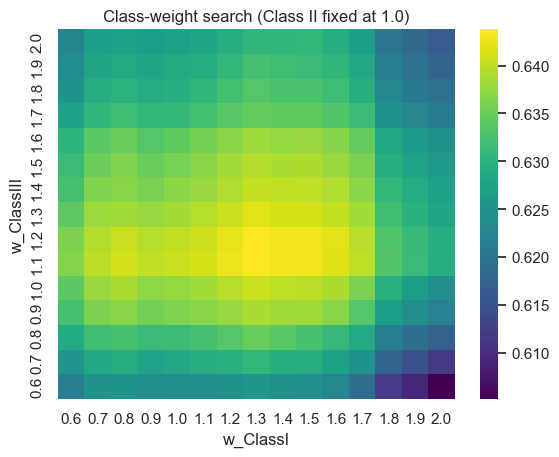

,OOF macro-F1
Logistic Regression (tuned),0.6368
LightGBM (tuned),0.6165
Blend (alpha=0.75),0.6376
Blend + class weights,0.6438


In [50]:
#Class-weight (threshold) search on the blend
#We search a grid on OOF data (not on test) and keep it only if it helps.
blend_oof = best_alpha * oof_lr + (1 - best_alpha) * oof_gbm

grid = np.round(np.arange(0.6, 2.01, 0.1), 2)
weight_rows = []
# Class II is fixed at 1; search Class I and Class III weights
for w1 in grid:
    for w3 in grid:
        weight_rows.append([w1, w3, macro_f1(y_train, blend_oof, (w1, 1, w3))])
gs = pd.DataFrame(weight_rows, columns=["w_ClassI", "w_ClassIII", "macro_F1"])

best_row = gs.sort_values("macro_F1", ascending=False).iloc[0]
best_w = (float(best_row["w_ClassI"]), 1.0, float(best_row["w_ClassIII"]))
print("Best class weights (I, II, III):", best_w, "-> OOF macro-F1 = %.4f" % best_row["macro_F1"])

# heatmap of macro-F1 for each weight pair
sns.heatmap(gs.pivot(index="w_ClassIII", columns="w_ClassI", values="macro_F1").iloc[::-1], cmap="viridis")
plt.title("Class-weight search (Class II fixed at 1.0)")
plt.show()

candidates_oof = pd.Series({
    "Logistic Regression (tuned)": macro_f1(y_train, oof_lr),
    "LightGBM (tuned)":            macro_f1(y_train, oof_gbm),
    "Blend (alpha=" + str(best_alpha) + ")": macro_f1(y_train, blend_oof),
    "Blend + class weights":       macro_f1(y_train, blend_oof, best_w),
}, name="OOF macro-F1")
candidates_oof.round(4).to_frame()

In [51]:
#pick the final model
#selection uses cross-validation results only

FINAL_NAME = candidates_oof.idxmax()
print("Selected final model:", FINAL_NAME)

# translate the choice into blend weight (alpha) and class weights
if FINAL_NAME == "Logistic Regression (tuned)":
    use_alpha, use_w = 1.0, (1, 1, 1)
elif FINAL_NAME == "LightGBM (tuned)":
    use_alpha, use_w = 0.0, (1, 1, 1)
elif FINAL_NAME == "Blend + class weights":
    use_alpha, use_w = best_alpha, best_w
else:
    use_alpha, use_w = best_alpha, (1, 1, 1)
print("alpha =", use_alpha, "| class weights =", use_w)

Selected final model: Blend + class weights
alpha = 0.75 | class weights = (1.3, 1.0, 1.1)


In [52]:
# fit on the full training set, transform the test set with the SAME fitted tools
# after choosing everything with CV, we refit on ALL training data. Test data is transformed with the tools learned on training data.
X_test_wide = apply_features(X_test, tools_wide)
X_test_lean = apply_features(X_test, tools_lean)

start = time.time()
# final Logistic Regression
lr_final = LogisticRegression(C=best_C, max_iter=400, class_weight="balanced").fit(X_train_wide, y_train)
#final light gbm
gbm_final = LGBMClassifier(subsample=0.8, subsample_freq=1, class_weight="balanced", n_jobs=1, random_state=42, verbose=-1,
                           **best_gbm_params).fit(X_train_lean, y_train)
print("final fits done in", round(time.time() - start), "seconds")

# blended probabilities for any new data
def final_proba(data):
    """Blend of the two models' probabilities for new data."""
    p_lr = lr_final.predict_proba(apply_features(data, tools_wide))
    p_gbm = gbm_final.predict_proba(apply_features(data, tools_lean))
    return use_alpha * p_lr + (1 - use_alpha) * p_gbm

# predicted class = highest (weighted) probability
def final_predict(data):
    return CLASSES[np.argmax(final_proba(data) * np.array(use_w), axis=1)]

final fits done in 42 seconds


In [53]:
#compare all models on the untouched test set
p_lr = lr_final.predict_proba(X_test_wide)
p_gbm = gbm_final.predict_proba(X_test_lean)
p_blend = best_alpha * p_lr + (1 - best_alpha) * p_gbm

dummy_pred = DummyClassifier(strategy="stratified", random_state=42).fit(X_train_lean, y_train).predict(X_test_lean)

test_predictions = {
    "Dummy (stratified)":          dummy_pred,
    "Logistic Regression (tuned)": CLASSES[p_lr.argmax(axis=1)],
    "LightGBM (tuned)":            CLASSES[p_gbm.argmax(axis=1)],
    "Blend (alpha=" + str(best_alpha) + ")": CLASSES[p_blend.argmax(axis=1)],
    "Blend + class weights":       CLASSES[(p_blend * np.array(best_w)).argmax(axis=1)],
}

rows = []
for name, pred in test_predictions.items():
    rows.append([name, accuracy_score(y_test, pred), balanced_accuracy_score(y_test, pred),
                 f1_score(y_test, pred, average="macro"), f1_score(y_test, pred, average="weighted"),
                 matthews_corrcoef(y_test, pred)])
# metrics: accuracy, balanced accuracy, macro-F1, weighted F1, MCC (MCC is a balanced single-number quality score)
test_tbl = pd.DataFrame(rows, columns=["model", "accuracy", "balanced_acc", "macro_F1", "weighted_F1", "MCC"]).set_index("model")
test_tbl["selected"] = ["<- FINAL" if name == FINAL_NAME else "" for name in test_tbl.index]
test_tbl.round(3)

,accuracy,balanced_acc,macro_F1,weighted_F1,MCC,selected
model,,,,,,
Dummy (stratified),0.436,0.323,0.322,0.436,-0.021,
Logistic Regression (tuned),0.795,0.673,0.665,0.798,0.634,
LightGBM (tuned),0.750,0.655,0.631,0.756,0.564,
Blend (alpha=0.75),0.797,0.682,0.673,0.799,0.638,
Blend + class weights,0.789,0.680,0.665,0.791,0.629,<- FINAL


In [54]:
#Detailed classification report of the final model
y_pred = final_predict(X_test)
print("FINAL MODEL:", FINAL_NAME)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))

FINAL MODEL: Blend + class weights

Classification Report:
              precision    recall  f1-score   support

     Class I      0.810     0.904     0.855      2596
    Class II      0.847     0.734     0.786      2952
   Class III      0.318     0.401     0.354       352

    accuracy                          0.789      5900
   macro avg      0.658     0.680     0.665      5900
weighted avg      0.799     0.789     0.791      5900



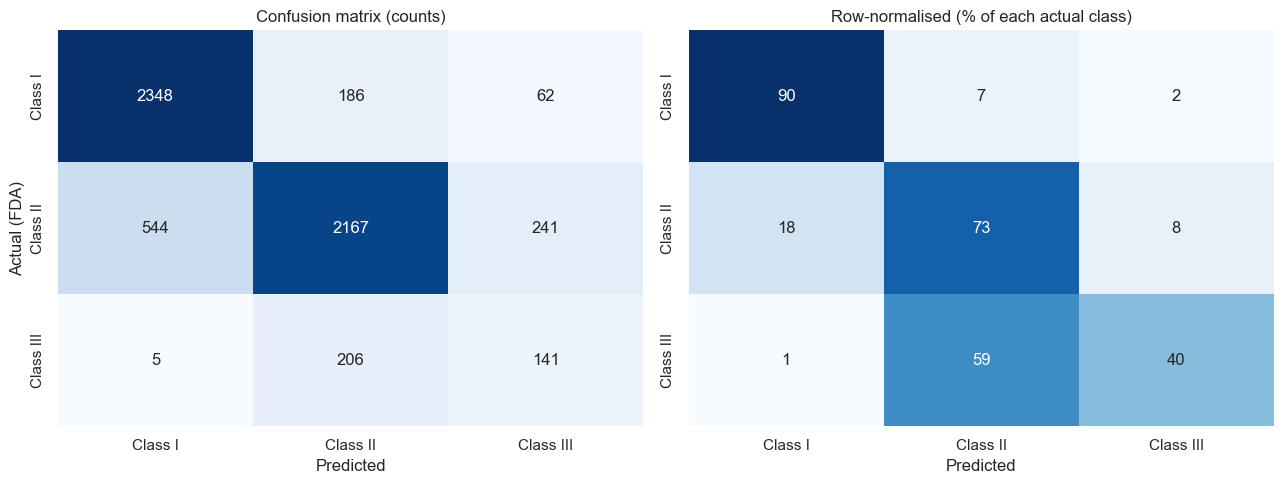

In [55]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=class_order)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_order, yticklabels=class_order, cbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual (FDA)")
sns.heatmap(cm_pct, annot=True, fmt=".0f", cmap="Blues", xticklabels=class_order, yticklabels=class_order, cbar=False, ax=axes[1])
axes[1].set_title("Row-normalised (% of each actual class)")
axes[1].set_xlabel("Predicted")
plt.tight_layout()
plt.show()

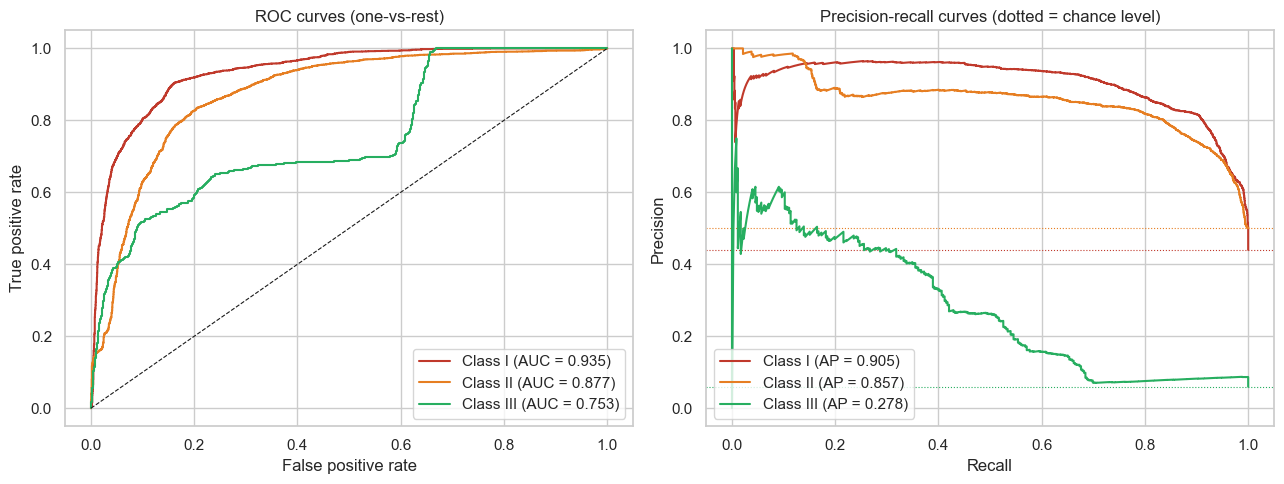

Macro one-vs-rest AUC: 0.855


In [56]:
 #ROC and precision-recall curves
#evaluate the ranking quality of probabilities independent of one threshold. ROC-AUC: 0.5 = random, 1 = perfect. Precision-recall is more informative for rare classes (dotted line = chance).
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

probs = final_proba(X_test)
y_bin = label_binarize(y_test, classes=class_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
auc_values = []
for i, (cls, col) in enumerate(zip(class_order, colors)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
    auc_values.append(auc(fpr, tpr))
    axes[0].plot(fpr, tpr, color=col, label=cls + " (AUC = " + str(round(auc_values[-1], 3)) + ")")

    precision, recall, _ = precision_recall_curve(y_bin[:, i], probs[:, i])
    ap = average_precision_score(y_bin[:, i], probs[:, i])
    axes[1].plot(recall, precision, color=col, label=cls + " (AP = " + str(round(ap, 3)) + ")")
    axes[1].axhline(y_bin[:, i].mean(), color=col, linestyle=":", linewidth=0.8)

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC curves (one-vs-rest)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend()
axes[1].set_title("Precision-recall curves (dotted = chance level)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Macro one-vs-rest AUC:", round(np.mean(auc_values), 3))

In [57]:
#Bootstrap confidence intervals
#test score is one number from one sample. Resampling whole events 300 times gives a 95% interval showing how uncertain the score is.
#We resample EVENTS (not rows) because products in an event are not independent.
np.random.seed(42)
test_events = g_test.unique()
rows_of_event = {e: np.where(g_test.values == e)[0] for e in test_events}
y_true_arr = y_test.values

boot_acc, boot_f1, boot_f1_c3 = [], [], []
for i in range(300):
    picked = np.random.choice(test_events, size=len(test_events), replace=True)     # resample whole events
    rows_idx = np.concatenate([rows_of_event[e] for e in picked])
    boot_acc.append(accuracy_score(y_true_arr[rows_idx], y_pred[rows_idx]))
    boot_f1.append(f1_score(y_true_arr[rows_idx], y_pred[rows_idx], average="macro"))
    boot_f1_c3.append(f1_score(y_true_arr[rows_idx], y_pred[rows_idx], labels=["Class III"], average=None)[0])

ci = pd.DataFrame({"accuracy": boot_acc, "macro_F1": boot_f1, "Class III F1": boot_f1_c3})
ci_table = pd.DataFrame({"mean": ci.mean(), "2.5%": ci.quantile(0.025), "97.5%": ci.quantile(0.975)})
ci_table.round(3)

,mean,2.5%,97.5%
accuracy,0.792,0.740,0.845
macro_F1,0.668,0.617,0.722
Class III F1,0.361,0.255,0.479


In [58]:
#ROBUSTNESS CHECKS
# Time-based validation (train on past, test on future)
# in real life we classify NEW recalls, so the model should work on future data. We train on <=2022 and test on 2023+
year = df_clean["report_year"]
train_time = np.where(year <= 2022)[0]
test_time = np.where(year >= 2023)[0]

# drop test events that also appear in the training period
train_events = set(df_clean["event_id"].iloc[train_time])
test_time = np.array([i for i in test_time if df_clean["event_id"].iloc[i] not in train_events])

X_tr_t, y_tr_t = X.iloc[train_time], y.iloc[train_time]
X_te_t, y_te_t = X.iloc[test_time], y.iloc[test_time]
print("Train (<=2022):", len(X_tr_t), "rows | Test (2023+):", len(X_te_t), "rows")
print("Class mix train (%):", (y_tr_t.value_counts(normalize=True)[class_order] * 100).round(1).to_dict())
print("Class mix test  (%):", (y_te_t.value_counts(normalize=True)[class_order] * 100).round(1).to_dict())

# same recipe as the final model, but trained only on the past
A_wide, tools_w_t = fit_features(X_tr_t)
A_lean, tools_l_t = fit_features(X_tr_t, max_reason=2500, max_desc=1500, scale=False)
lr_t = LogisticRegression(C=best_C, max_iter=400, class_weight="balanced").fit(A_wide, y_tr_t)
gbm_t = LGBMClassifier(subsample=0.8, subsample_freq=1, class_weight="balanced", n_jobs=1, random_state=42, verbose=-1,
                       **best_gbm_params).fit(A_lean, y_tr_t)

# blended probabilities for the future data
p_t = (use_alpha * lr_t.predict_proba(apply_features(X_te_t, tools_w_t))
       + (1 - use_alpha) * gbm_t.predict_proba(apply_features(X_te_t, tools_l_t)))
pred_t = CLASSES[np.argmax(p_t * np.array(use_w), axis=1)]

# results on the future period
print("\nTIME-BASED RESULT -> accuracy %.3f | macro-F1 %.3f | MCC %.3f" % (
    accuracy_score(y_te_t, pred_t), f1_score(y_te_t, pred_t, average="macro"), matthews_corrcoef(y_te_t, pred_t)))
print(classification_report(y_te_t, pred_t, digits=3))

Train (<=2022): 23275 rows | Test (2023+): 6228 rows
Class mix train (%): {'Class I': 43.4, 'Class II': 51.1, 'Class III': 5.5}
Class mix test  (%): {'Class I': 46.2, 'Class II': 45.9, 'Class III': 7.9}

TIME-BASED RESULT -> accuracy 0.695 | macro-F1 0.608 | MCC 0.460
              precision    recall  f1-score   support

     Class I      0.739     0.779     0.758      2877
    Class II      0.687     0.670     0.678      2860
   Class III      0.428     0.356     0.389       491

    accuracy                          0.695      6228
   macro avg      0.618     0.602     0.608      6228
weighted avg      0.691     0.695     0.692      6228



In [59]:
# re-trains the model with only some feature groups.
no_text = dict(use_reason=False, use_desc=False)
variants = {
    "Structured fields only":              dict(use_reason=False, use_desc=False),
    "Product description text only":       dict(use_reason=False, use_cat=False, use_num=False, use_flags=False),
    "Reason-for-recall text only":         dict(use_desc=False, use_cat=False, use_num=False, use_flags=False),
    "Both texts (no structured fields)":   dict(use_cat=False, use_num=False, use_flags=False),
    "Everything (final feature set)":      dict(),
    "Everything minus report month & state": dict(cats=[c for c in cat_cols if c not in ("report_month_c", "state_grp")]),
}

ablation_rows = []
# evaluate each variant with grouped CV
for name, settings in variants.items():
    fold_data = build_folds(folds, **settings)
    scores = cv_score(LogisticRegression(C=best_C, max_iter=400, class_weight="balanced"), fold_data)
    ablation_rows.append([name, scores["accuracy"], scores["f1_macro"]])
    print(name, "-> macro-F1:", round(scores["f1_macro"], 3))

ab = pd.DataFrame(ablation_rows, columns=["inputs", "accuracy", "macro_F1"]).set_index("inputs")
ab.round(3)

Structured fields only -> macro-F1: 0.565
Product description text only -> macro-F1: 0.444
Reason-for-recall text only -> macro-F1: 0.6
Both texts (no structured fields) -> macro-F1: 0.599
Everything (final feature set) -> macro-F1: 0.637
Everything minus report month & state -> macro-F1: 0.644


,accuracy,macro_F1
inputs,,
Structured fields only,0.660,0.565
Product description text only,0.557,0.444
Reason-for-recall text only,0.696,0.600
Both texts (no structured fields),0.707,0.599
Everything (final feature set),0.753,0.637
Everything minus report month & state,0.761,0.644


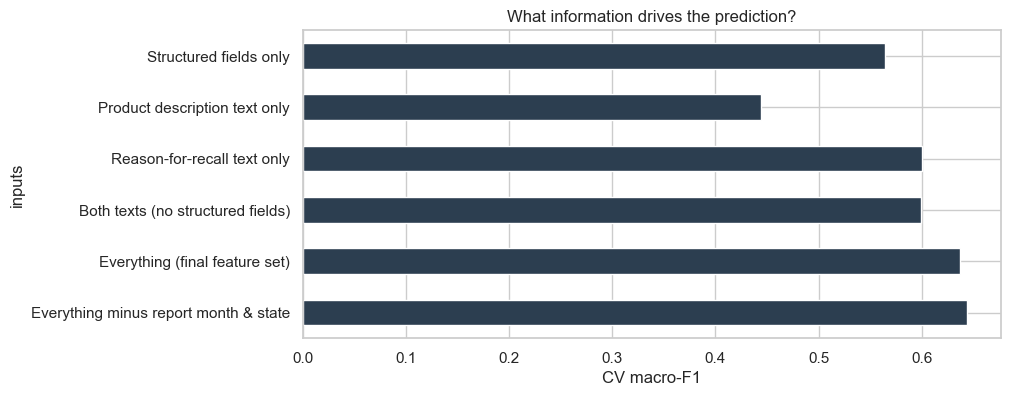

In [60]:
#Plot ablation results
ab["macro_F1"].plot(kind="barh", figsize=(9, 4), color="#2c3e50")
plt.gca().invert_yaxis()
plt.xlabel("CV macro-F1")
plt.title("What information drives the prediction?")
plt.show()

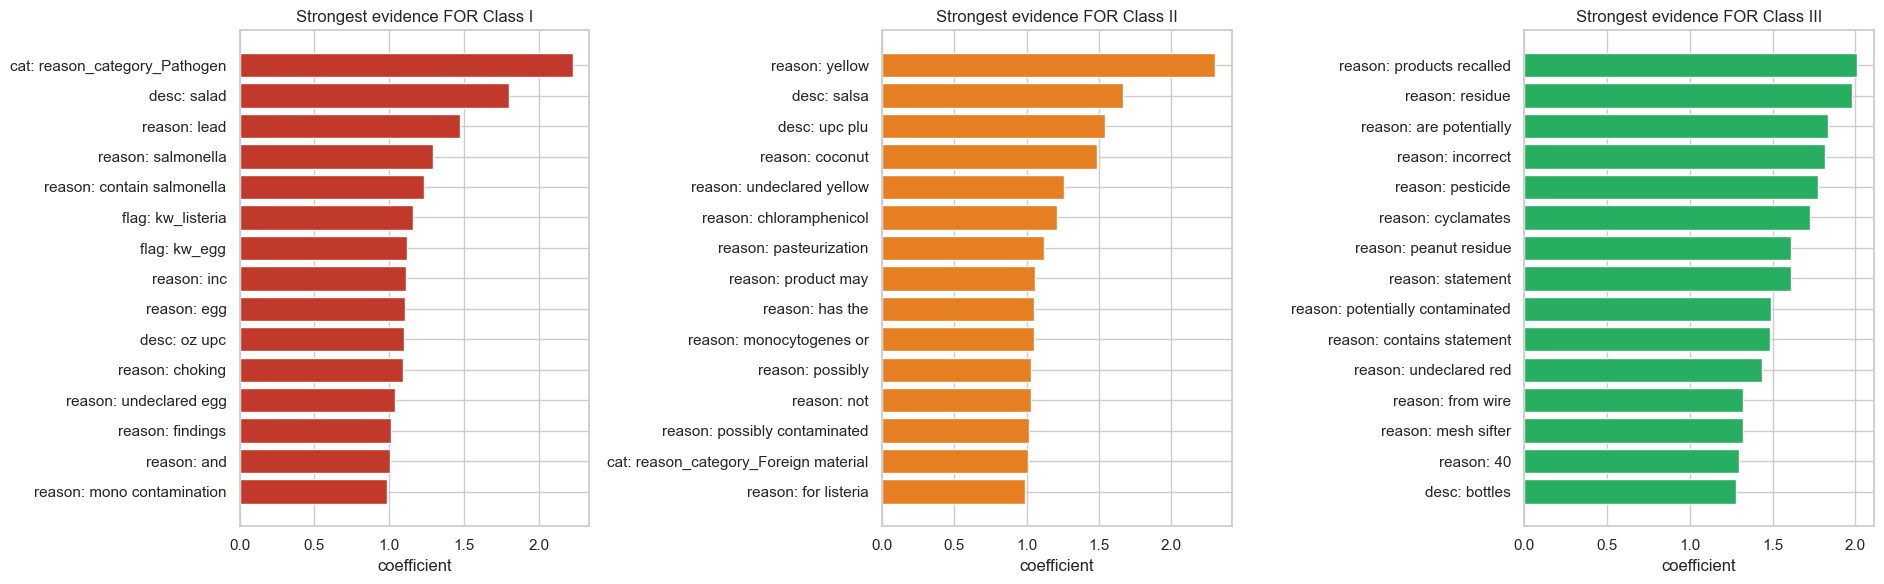

In [61]:
# MODEL INTERPRETATION
# Logistic Regression coefficients
lr_names = np.array(get_feature_names(tools_wide))
coefficients = lr_final.coef_

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for i, (cls, col) in enumerate(zip(lr_final.classes_, colors)):
    top = np.argsort(coefficients[i])[::-1][:15]
    axes[i].barh(lr_names[top][::-1], coefficients[i][top][::-1], color=col)
    axes[i].set_title("Strongest evidence FOR " + cls)
    axes[i].set_xlabel("coefficient")
plt.tight_layout()
plt.show()

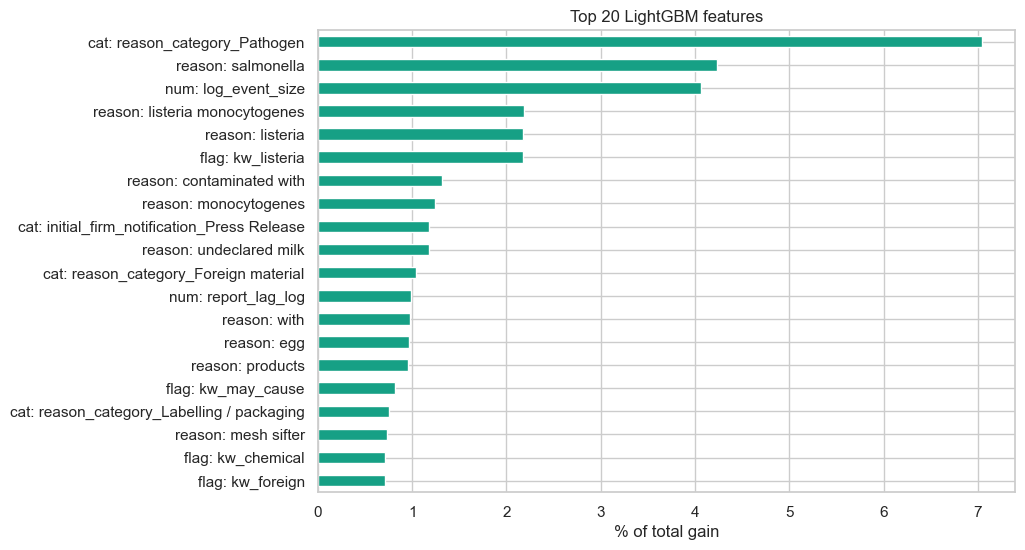

In [62]:
#LightGBM feature importance
gbm_names = np.array(get_feature_names(tools_lean))
importance = pd.Series(gbm_final.booster_.feature_importance("gain"), index=gbm_names)
importance = (importance / importance.sum() * 100).sort_values(ascending=False).head(20)

importance[::-1].plot(kind="barh", figsize=(9, 6), color="#16a085")
plt.xlabel("% of total gain")
plt.title("Top 20 LightGBM features")
plt.show()

Baseline test macro-F1: 0.665


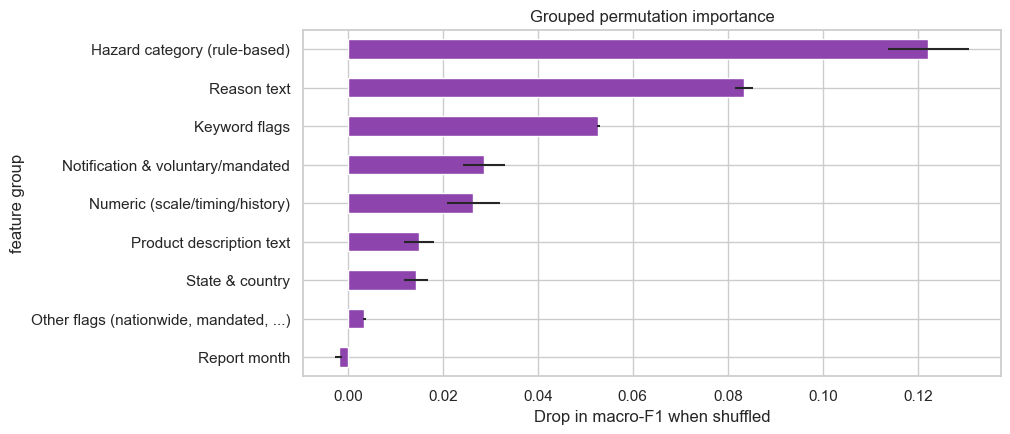

,macro-F1 drop,sd
feature group,,
Hazard category (rule-based),0.1222,0.0086
Reason text,0.0834,0.0020
Keyword flags,0.0527,0.0003
Notification & voluntary/mandated,0.0286,0.0044
Numeric (scale/timing/history),0.0265,0.0056
Product description text,0.0150,0.0031
State & country,0.0143,0.0025
"Other flags (nationwide, mandated, ...)",0.0035,0.0003
Report month,-0.0019,0.0008


In [63]:
# Grouped permutation importance
#A big drop = the model relies on that group. Grouping avoids splitting importance across thousands of correlated word columns.
column_groups = {
    "Reason text":                       ["reason_for_recall"],
    "Product description text":          ["product_description"],
    "Hazard category (rule-based)":      ["reason_category"],
    "Report month":                      ["report_month_c"],
    "State & country":                   ["state_grp", "country_grp"],
    "Notification & voluntary/mandated": ["initial_firm_notification", "voluntary_mandated"],
    "Numeric (scale/timing/history)":    num_cols,
    "Keyword flags":                     list(keywords),
    "Other flags (nationwide, mandated, ...)": ["is_nationwide", "is_international", "quantity_missing", "codes_missing", "is_mandated"],
}

base_score = f1_score(y_test, final_predict(X_test), average="macro")
print("Baseline test macro-F1: %.3f" % base_score)

perm_rows = []
for group_name, cols in column_groups.items():
    drops = []
    for repeat in range(3):
        X_shuffled = X_test.copy()
        X_shuffled[cols] = X_shuffled[cols].sample(frac=1, random_state=repeat).values     # break the link with the label
        drops.append(base_score - f1_score(y_test, final_predict(X_shuffled), average="macro"))
    perm_rows.append([group_name, np.mean(drops), np.std(drops)])

perm = pd.DataFrame(perm_rows, columns=["feature group", "macro-F1 drop", "sd"]).set_index("feature group")
perm = perm.sort_values("macro-F1 drop", ascending=False)

perm["macro-F1 drop"].plot(kind="barh", xerr=perm["sd"], figsize=(9, 4.5), color="#8e44ad")
plt.gca().invert_yaxis()
plt.xlabel("Drop in macro-F1 when shuffled")
plt.title("Grouped permutation importance")
plt.show()
perm.round(4)

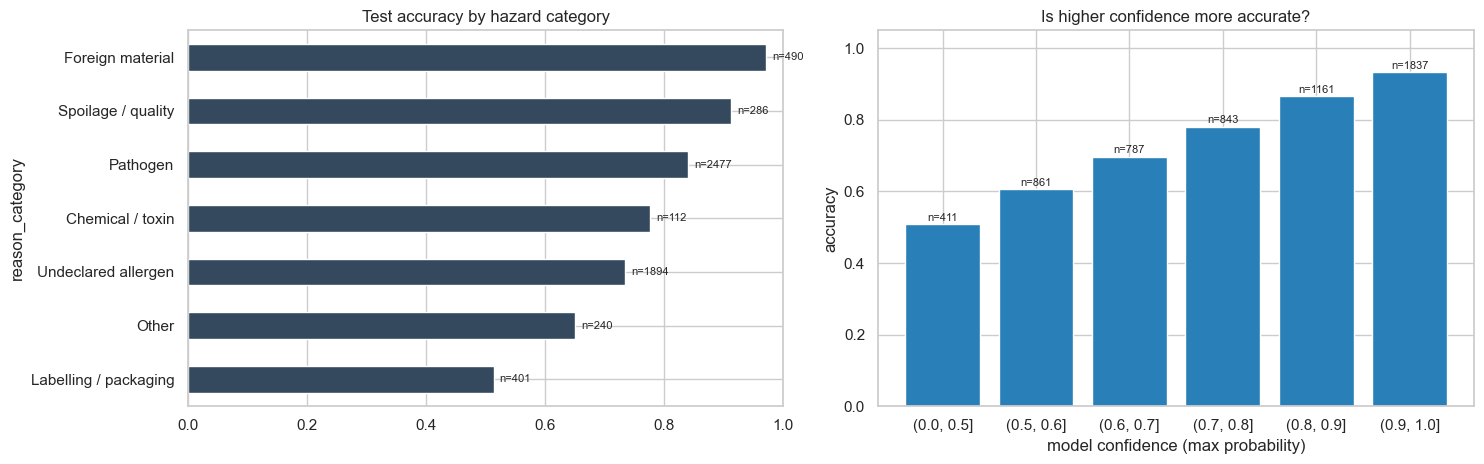

In [64]:
#ERROR ANALYSIS
#accuracy by hazard category shows weak areas; accuracy by confidence level checks whether the model's confidence is trustworthy (higher confidence should mean higher accuracy).
err = X_test.copy()
err["actual"] = y_test.values
err["pred"] = y_pred
err["correct"] = err["actual"] == err["pred"]
err["confidence"] = final_proba(X_test).max(axis=1)
err["year"] = df_clean.loc[test_idx, "report_year"].values

by_cat = err.groupby("reason_category")["correct"].agg(["size", "mean"]).sort_values("mean")
err["conf_bin"] = pd.cut(err["confidence"], [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
by_conf = err.groupby("conf_bin", observed=True)["correct"].agg(["size", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
by_cat["mean"].plot(kind="barh", ax=axes[0], color="#34495e")
axes[0].set_xlim(0, 1)
axes[0].set_title("Test accuracy by hazard category")
for i, (name, row) in enumerate(by_cat.iterrows()):
    axes[0].text(row["mean"] + 0.01, i, "n=" + str(int(row["size"])), va="center", fontsize=8)

axes[1].bar(by_conf.index.astype(str), by_conf["mean"], color="#2980b9")
for i, (name, row) in enumerate(by_conf.iterrows()):
    axes[1].text(i, row["mean"] + 0.01, "n=" + str(int(row["size"])), ha="center", fontsize=8)
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Is higher confidence more accurate?")
axes[1].set_xlabel("model confidence (max probability)")
axes[1].set_ylabel("accuracy")
plt.tight_layout()
plt.show()

In [83]:
# the most confidently wrong predictions
wrong = err[~err["correct"]].sort_values("confidence", ascending=False)
show = wrong[["actual", "pred", "confidence", "reason_for_recall"]].head(12).copy()
show["confidence"] = show["confidence"].round(2)
show["reason_for_recall"] = show["reason_for_recall"].str.slice(0, 170)
show.reset_index(drop=True)

,actual,pred,confidence,reason_for_recall
0,Class II,Class I,0.99,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
1,Class II,Class I,0.98,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
2,Class II,Class I,0.98,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
3,Class II,Class I,0.98,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
4,Class III,Class II,0.98,Downstream Recall - Possible metal fragments in starch that was used to manu...
5,Class II,Class I,0.98,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
6,Class II,Class I,0.98,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
7,Class II,Class I,0.98,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
8,Class II,Class I,0.98,"Wegmans Food Markets, Inc. voluntarily recalled fresh individually sold, bag..."
9,Class III,Class II,0.98,"May contain small pieces of metal, approximately 1mm or less in size"


In [66]:
# Class III is the hardest class: what is it confused with?\
#This shows how many are found and which classes they are mistaken for.
class3 = err[err["actual"] == "Class III"]
print("Class III test rows:", len(class3), "| predicted correctly:", int(class3["correct"].sum()), "(" + str(round(class3["correct"].mean() * 100)) + "%)")
print("Where the missed Class III rows went:", class3.loc[~class3["correct"], "pred"].value_counts().to_dict())

missed = class3[~class3["correct"]][["reason_for_recall"]].head(6).copy()
missed["reason_for_recall"] = missed["reason_for_recall"].str.slice(0, 190)
missed.reset_index(drop=True)

Class III test rows: 352 | predicted correctly: 141 (40%)
Where the missed Class III rows went: {'Class II': 206, 'Class I': 5}


,reason_for_recall
0,Recall initiated due to the wrong best by date (1-11-2025) being printed on ...
1,Sea Salt Almond Allegator candy has a back label for chocolate covered cherr...
2,Dips and sauces received out of temperature specifications. Product was not ...
3,Dips and sauces received out of temperature specifications. Product was not ...
4,Dips and sauces received out of temperature specifications. Product was not ...
5,Dips and sauces received out of temperature specifications. Product was not ...


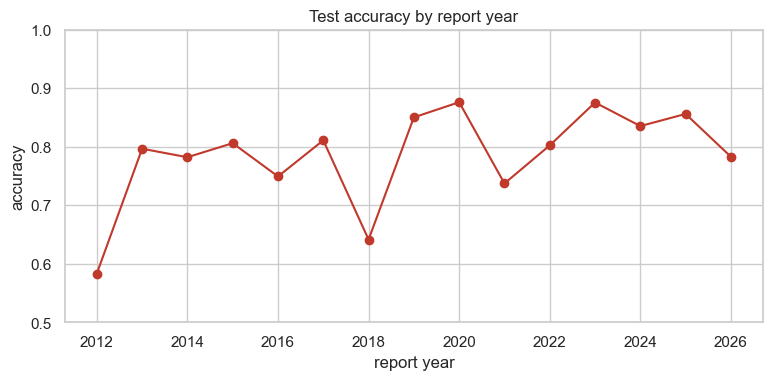

In [67]:
# is the accuracy changing over the years?
by_year = err.groupby("year")["correct"].agg(["size", "mean"])
plt.figure(figsize=(9, 3.8))
plt.plot(by_year.index, by_year["mean"], marker="o", color="#c0392b")
plt.ylim(0.5, 1)
plt.title("Test accuracy by report year")
plt.xlabel("report year")
plt.ylabel("accuracy")
plt.show()

In [ ]:
#save the trained model
import joblib, os

# everything needed to predict
bundle = {"lr": lr_final, "gbm": gbm_final, "tools_wide": tools_wide, "tools_lean": tools_lean,
          "alpha": use_alpha, "class_weights": use_w, "features": all_features, "final_model": FINAL_NAME}
# write to disk (compressed)
joblib.dump(bundle, "fda_recall_model.joblib", compress=3)
print("Saved fda_recall_model.joblib (%.1f MB)" % (os.path.getsize("fda_recall_model.joblib") / 1e6))

In [ ]:
# Function to classify ONE new recall
def classify_new_recall(reason, description, quantity_text="", distribution="", state="Unknown", country="United States",
                        voluntary="Voluntary: Firm initiated", notification="Email", report_month=6, report_lag_days=45,
                        n_products_in_event=1, firm_prior_events=0, code_info="no codes"):
    """Build the same features for ONE new recall and return the predicted class + probabilities."""
    # start the one-row table
    row = pd.DataFrame({"reason_for_recall": [reason], "product_description": [description]})

    # categories
    row["state_grp"] = state if state in list(top_25_states) else "Other"
    row["country_grp"] = country if country in ["United States", "Canada"] else "Other"
    row["voluntary_mandated"] = voluntary
    row["initial_firm_notification"] = notification
    row["reason_category"] = get_reason_category(reason)
    row["report_month_c"] = str(report_month)

    # numbers
    quantity = get_quantity(quantity_text)
    row["log_quantity"] = np.log10(max(quantity, 1)) if not np.isnan(quantity) else np.nan
    row["n_states"] = count_states(distribution)
    row["report_lag_log"] = np.log1p(report_lag_days)
    row["reason_words"] = len(reason.split())
    row["desc_words"] = len(description.split())
    row["log_event_size"] = np.log1p(n_products_in_event)
    row["firm_prior_log"] = np.log1p(firm_prior_events)

    # flags
    dist_text = distribution.lower()
    row["is_nationwide"] = int(any(w in dist_text for w in ["nationwide", "nation wide", "nationally", "all states", "50 states"]))
    row["is_international"] = int(any(w in dist_text for w in ["canada", "mexico", "international", "worldwide", "foreign", "export"]))
    row["quantity_missing"] = int(np.isnan(quantity))
    row["codes_missing"] = int(code_info.lower().strip() in ["", "no codes", "none", "n/a", "unknown", "not available"])
    row["is_mandated"] = int(voluntary == "FDA Mandated")
    for name, word_list in keywords.items():
        row[name] = int(any(w in reason.lower() for w in word_list))

    # blended probabilities -> weighted decision
    probs = final_proba(row[all_features])
    predicted = CLASSES[np.argmax(probs * np.array(use_w), axis=1)][0]
    return predicted, {str(c): round(float(p), 3) for c, p in zip(CLASSES, probs[0])}

In [70]:
#demo with 3 example

examples = [
    ("Product may be contaminated with Listeria monocytogenes.", "Fresh soft cheese, 8 oz packages", "5,000 cases", "Distributed nationwide", "CA"),
    ("Product contains undeclared milk allergen; label does not list milk.", "Chocolate chip cookies, 12 ct box", "800 cases", "TX, OK, LA", "TX"),
    ("Product labelled with incorrect net weight on the package.", "Dried mango slices, 6 oz bag", "200 cases", "FL", "FL"),
]

for example in examples:
    predicted, probs = classify_new_recall(*example)
    print(example[0][:62].ljust(64), "->", predicted, probs)

Product may be contaminated with Listeria monocytogenes.         -> Class I {'Class I': 0.933, 'Class II': 0.062, 'Class III': 0.005}
Product contains undeclared milk allergen; label does not list   -> Class II {'Class I': 0.421, 'Class II': 0.565, 'Class III': 0.014}
Product labelled with incorrect net weight on the package.       -> Class III {'Class I': 0.03, 'Class II': 0.069, 'Class III': 0.9}
